# Beginning

In [1]:
# Все библиотеки

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.stats import ttest_ind, levene, mannwhitneyu,shapiro, \
    f_oneway, kruskal, chi2_contingency, fisher_exact
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scikit_posthocs as sp
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import pingouin as pg
import sys
import os
from ydata_profiling import ProfileReport
from matplotlib import rcParams
from matplotlib import font_manager as fm
import matplotlib as mpl
import warnings

mpl.rcParams['font.family'] = 'HSE Sans'
plt.rcParams['figure.dpi'] = 300

warnings.filterwarnings('ignore')

import graphics
import tests

/Users/ssd/Documents/src/dano_base/base/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
#df = pd.read_excel("data.xlsx")
df = pd.read_csv("data.csv")
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.head(5)

,policy_rk,coverage,repair_option,region,auto_make,auto_model,insurant_gender_cd,total_premium_amt,paid_flg,auto_cost,...,expected_loss_amt,transition_flg,premium_transition_amt,renewed_issue_flg,renewed_paid_flg,k,age_of_car,new_and_credit,new_or_credit,new_credit
0,283363056,Полное КАСКО,Ремонт на СТОА официального дилера,Иркутская область,Mazda,Mazda CX-9,M,787323.60,1,2340000.0,...,0.000,0.0,0.0,0,0,2.972094,4.0,0.0,0.0,0.0
1,283392099,Полное КАСКО,Ремонт на СТОА официального дилера,Москва,Subaru,Subaru Legacy,M,33526.08,1,1765800.0,...,0.000,0.0,0.0,1,1,52.669444,3.0,0.0,0.0,0.0
2,283592373,Полное КАСКО,Ремонт на СТОА официального дилера,Москва,Nissan,Nissan X-Trail,M,540900.00,0,2200000.0,...,175635.000,0.0,0.0,0,0,4.067295,1.0,0.0,1.0,1.0
3,283594449,Полное КАСКО,Ремонт на СТОА официального дилера,Москва,Mini (BMW),Mini (BMW) Countryman,F,374400.00,0,2325000.0,...,124295.265,1.0,626679.0,0,0,6.209936,2.0,0.0,0.0,0.0
4,283594911,Полное КАСКО,Ремонт на СТОА по направлению страховщика,Санкт-Петербург,Renault,Renault Kaptur,F,231300.00,1,1390000.0,...,124247.160,0.0,0.0,0,0,6.009511,4.0,0.0,0.0,0.0


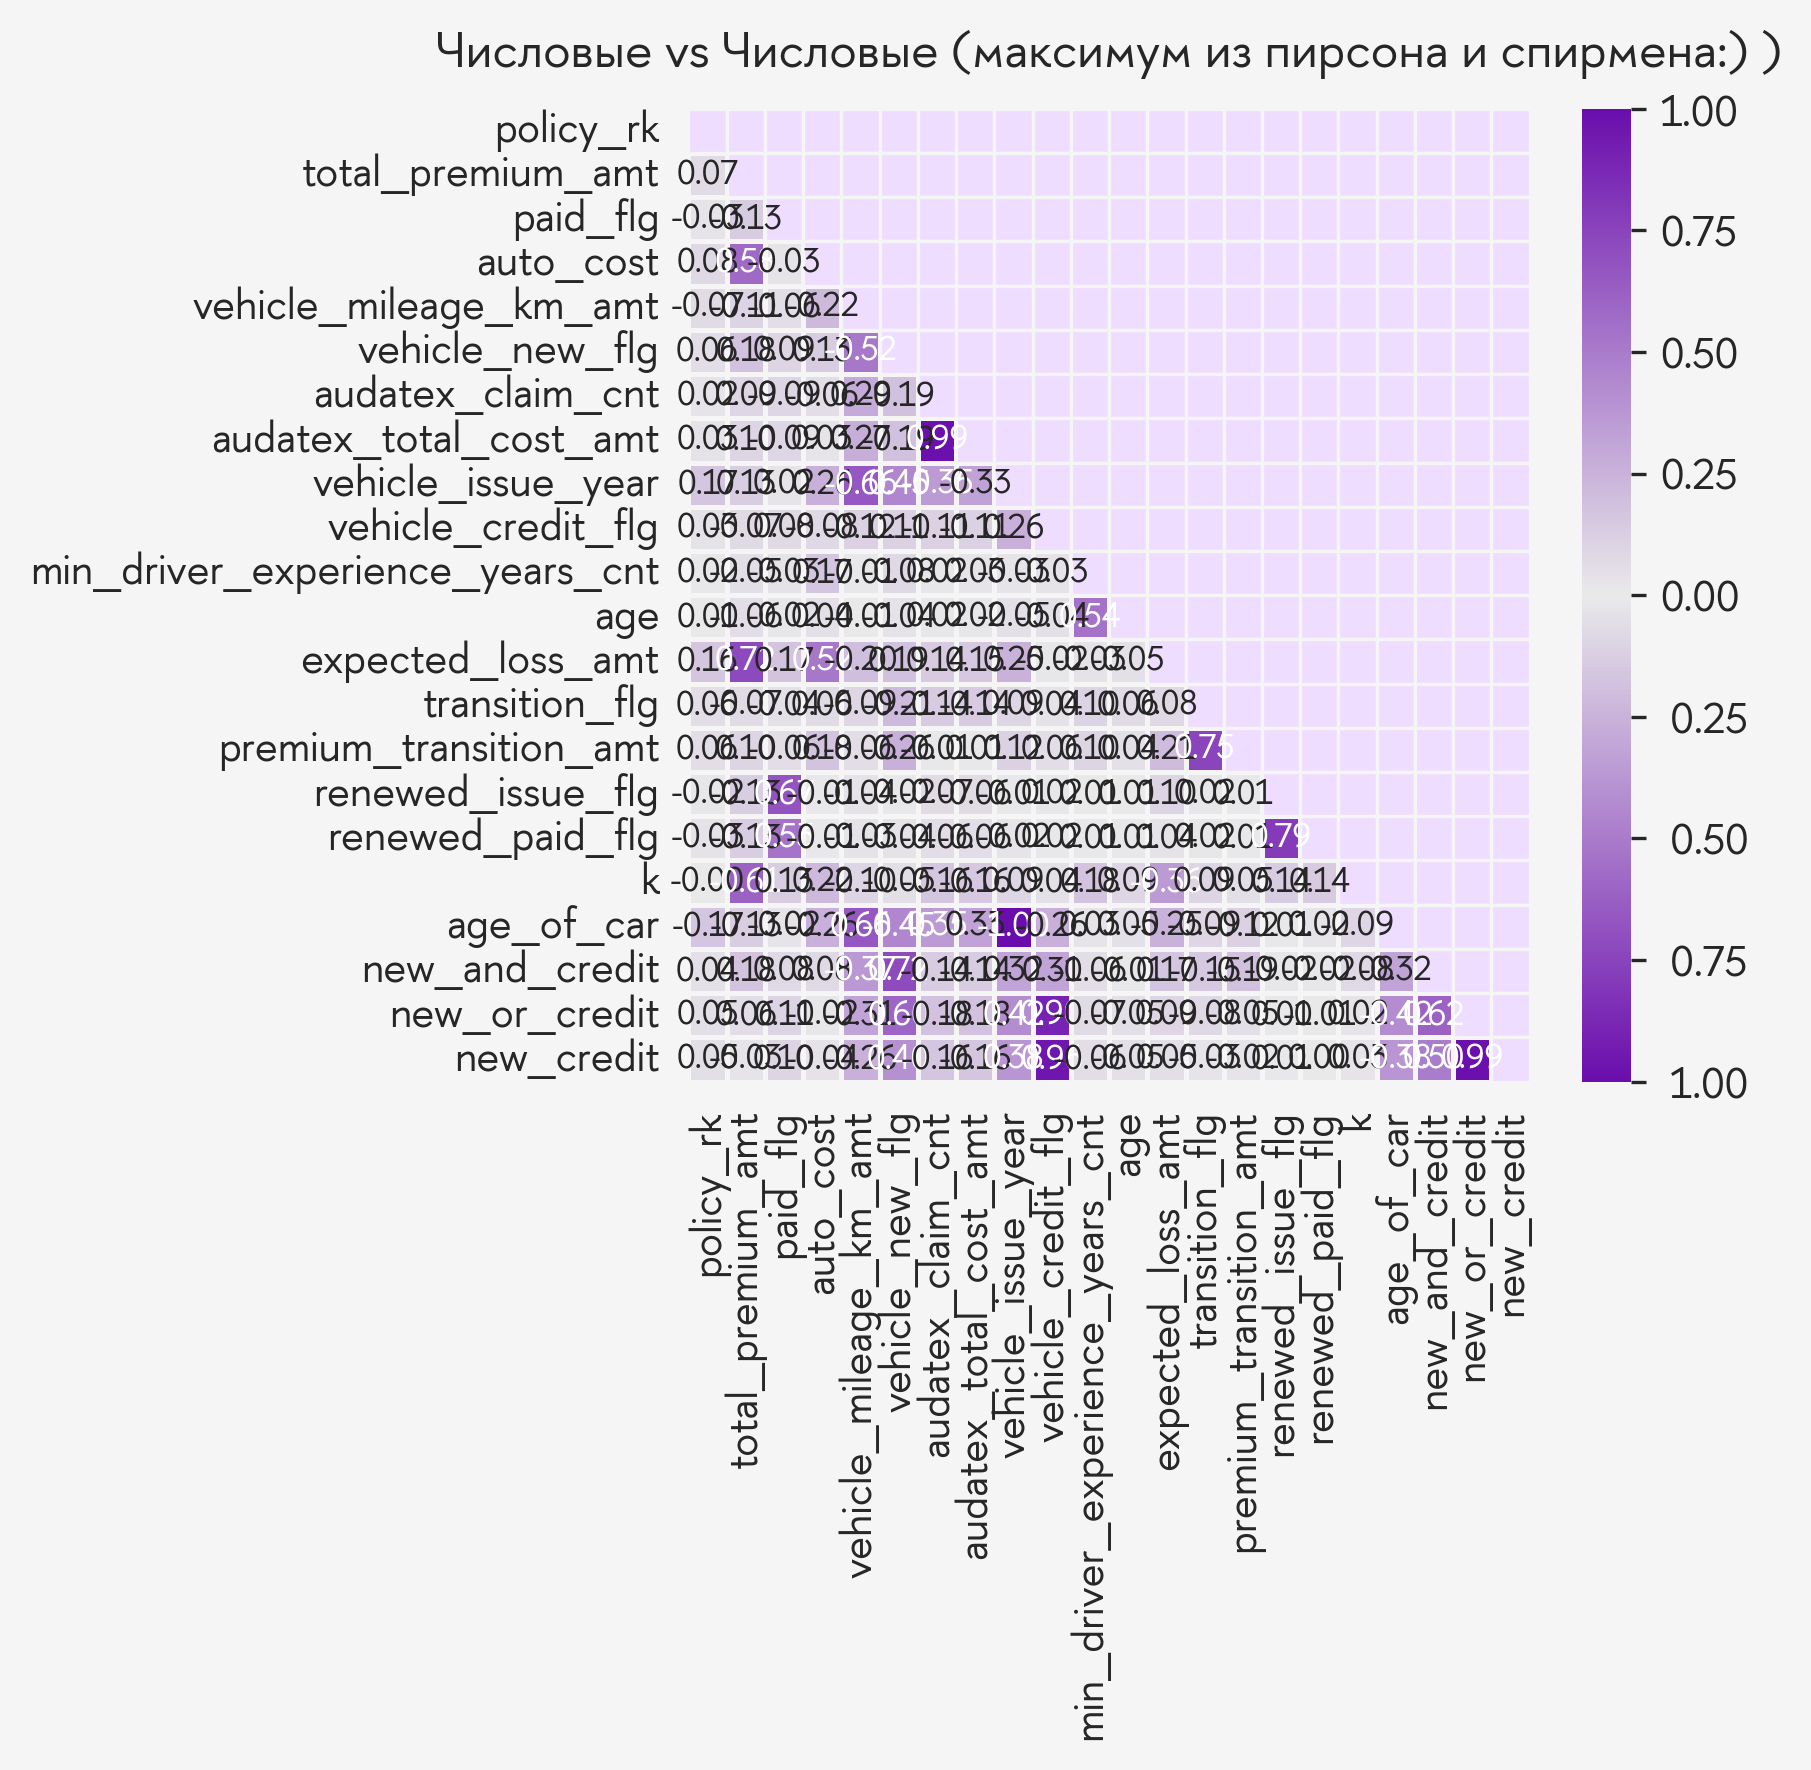

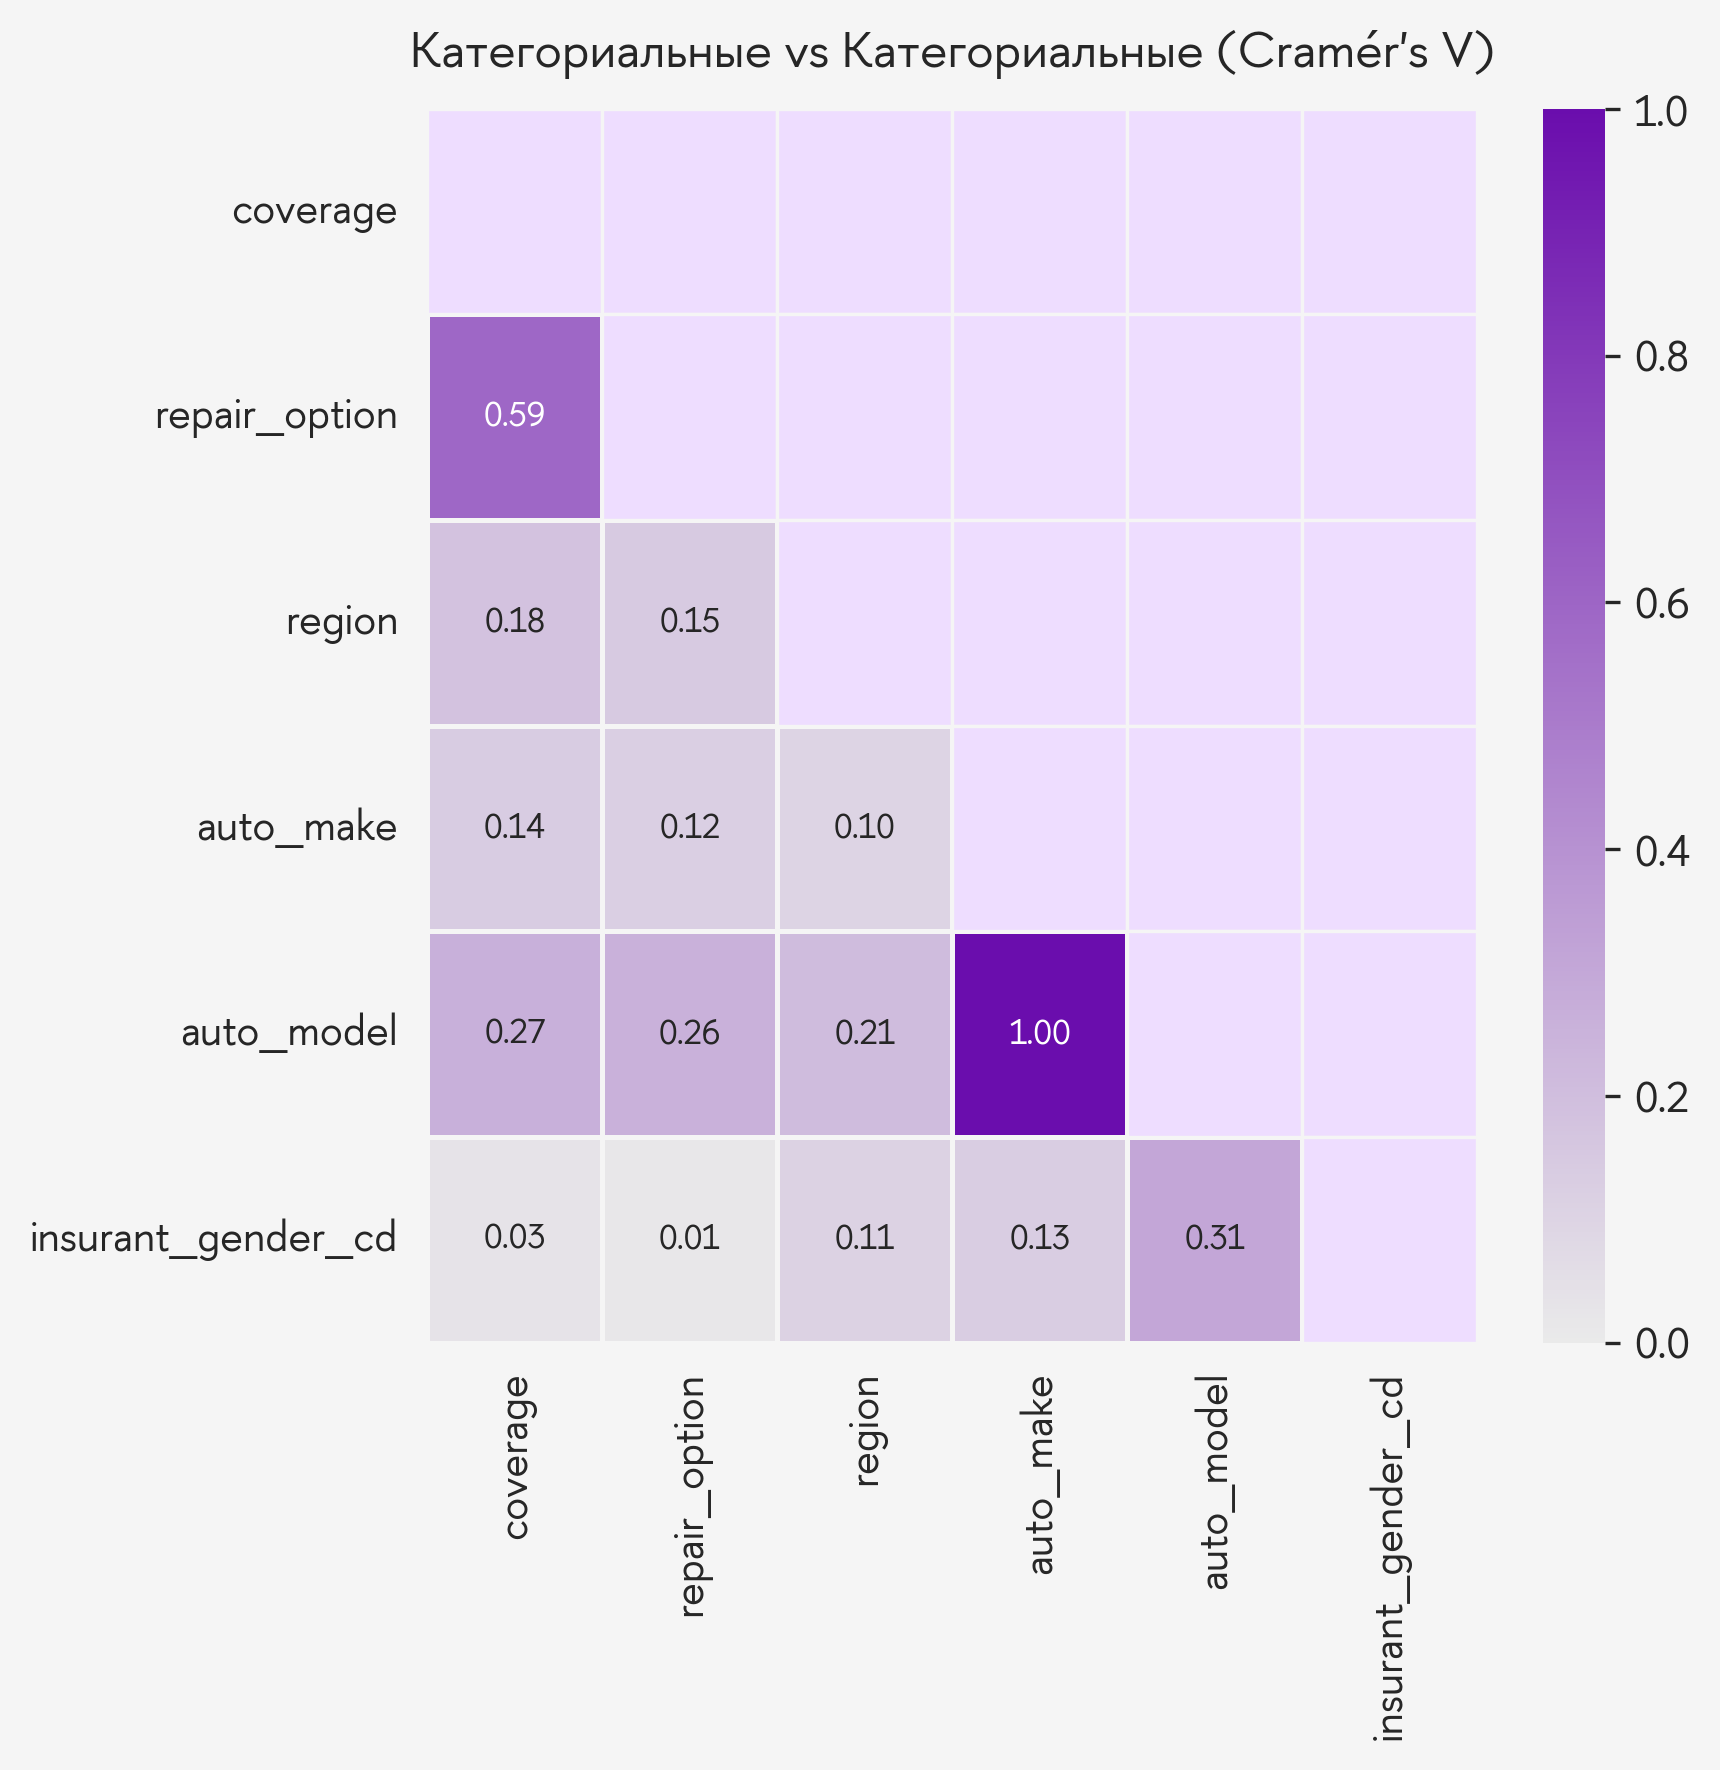

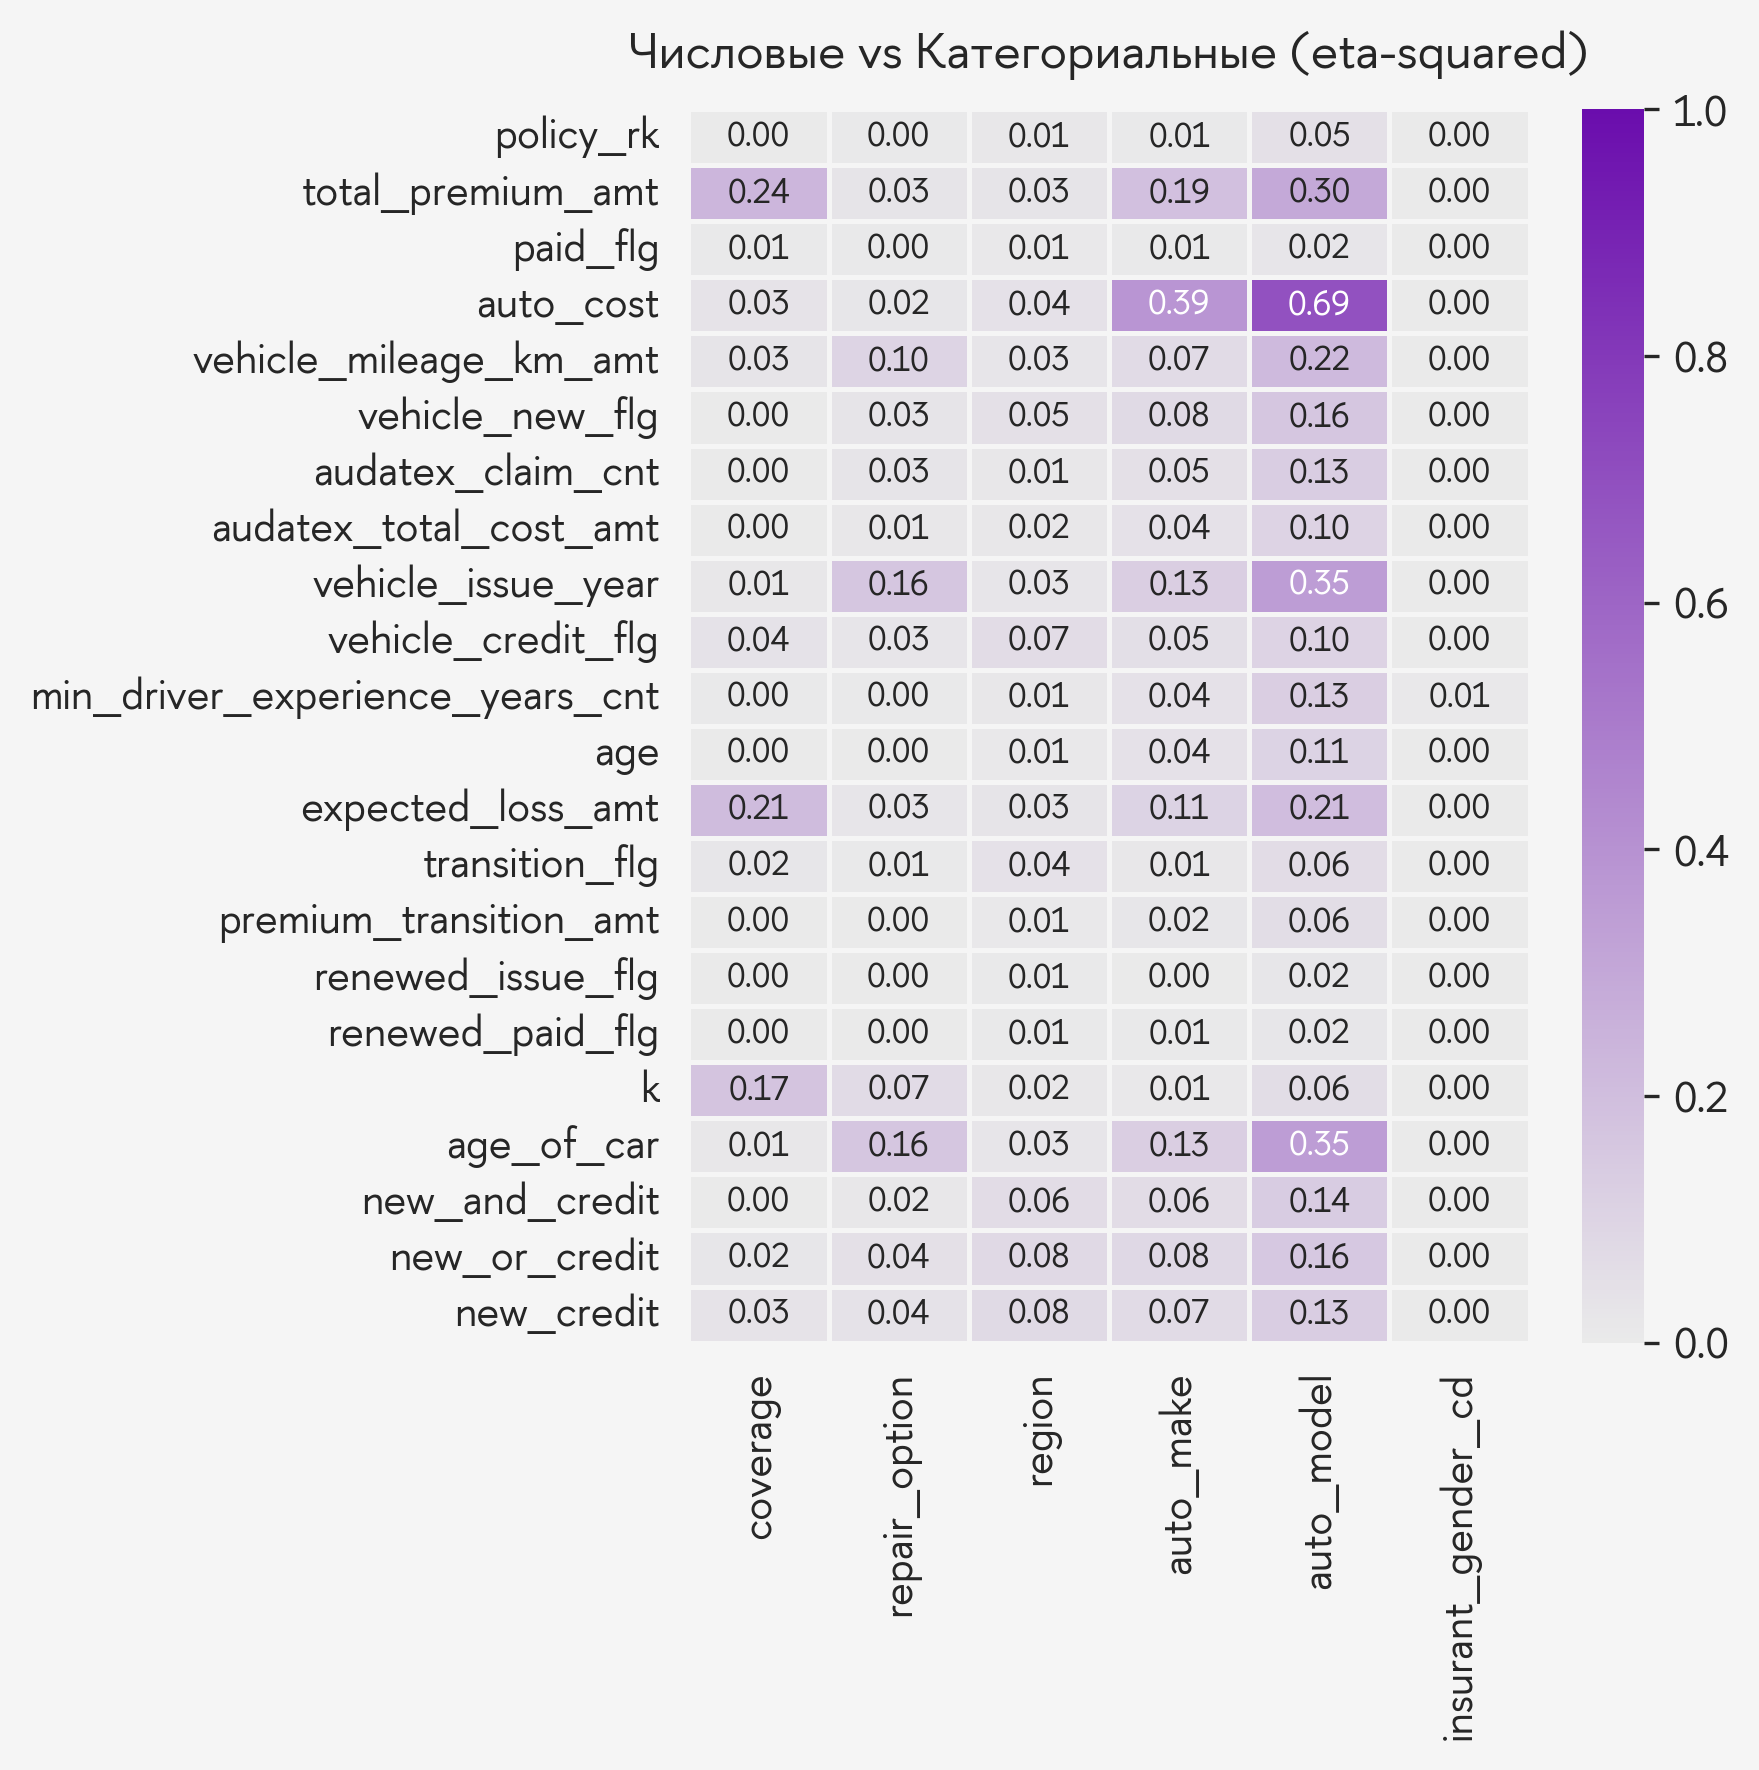

{'num_num':                                  policy_rk  total_premium_amt  paid_flg  \
 policy_rk                         1.000000           0.065703 -0.031229   
 total_premium_amt                 0.065703           1.000000 -0.133599   
 paid_flg                         -0.031229          -0.133599  1.000000   
 auto_cost                         0.081475           0.584999 -0.030556   
 vehicle_mileage_km_amt           -0.066438          -0.106336 -0.062352   
 vehicle_new_flg                   0.059486           0.182369  0.094655   
 audatex_claim_cnt                 0.024814           0.090742 -0.091846   
 audatex_total_cost_amt            0.034689           0.100053 -0.090132   
 vehicle_issue_year                0.166162           0.129868  0.024114   
 vehicle_credit_flg                0.032008          -0.070654  0.075344   
 min_driver_experience_years_cnt   0.015398          -0.054558 -0.032111   
 age                               0.007314          -0.057332 -0.018165   
 

In [3]:
graphics.mixed_corr_heatmaps(df)

In [ ]:
profile = ProfileReport(df, title="Profiling Report", correlations={
    "auto": {"calculate": True},
    "pearson": {"calculate": True},
    "spearman": {"calculate": True},
    "kendall": {"calculate": True},
    "phi_k": {"calculate": True},
    "cramers": {"calculate": True},
})
profile

In [ ]:
variances_to_find_outliers = []

for var in variances_to_find_outliers:
    graphics.norm_hist(df[var])

1) Bar chart: categories A..E


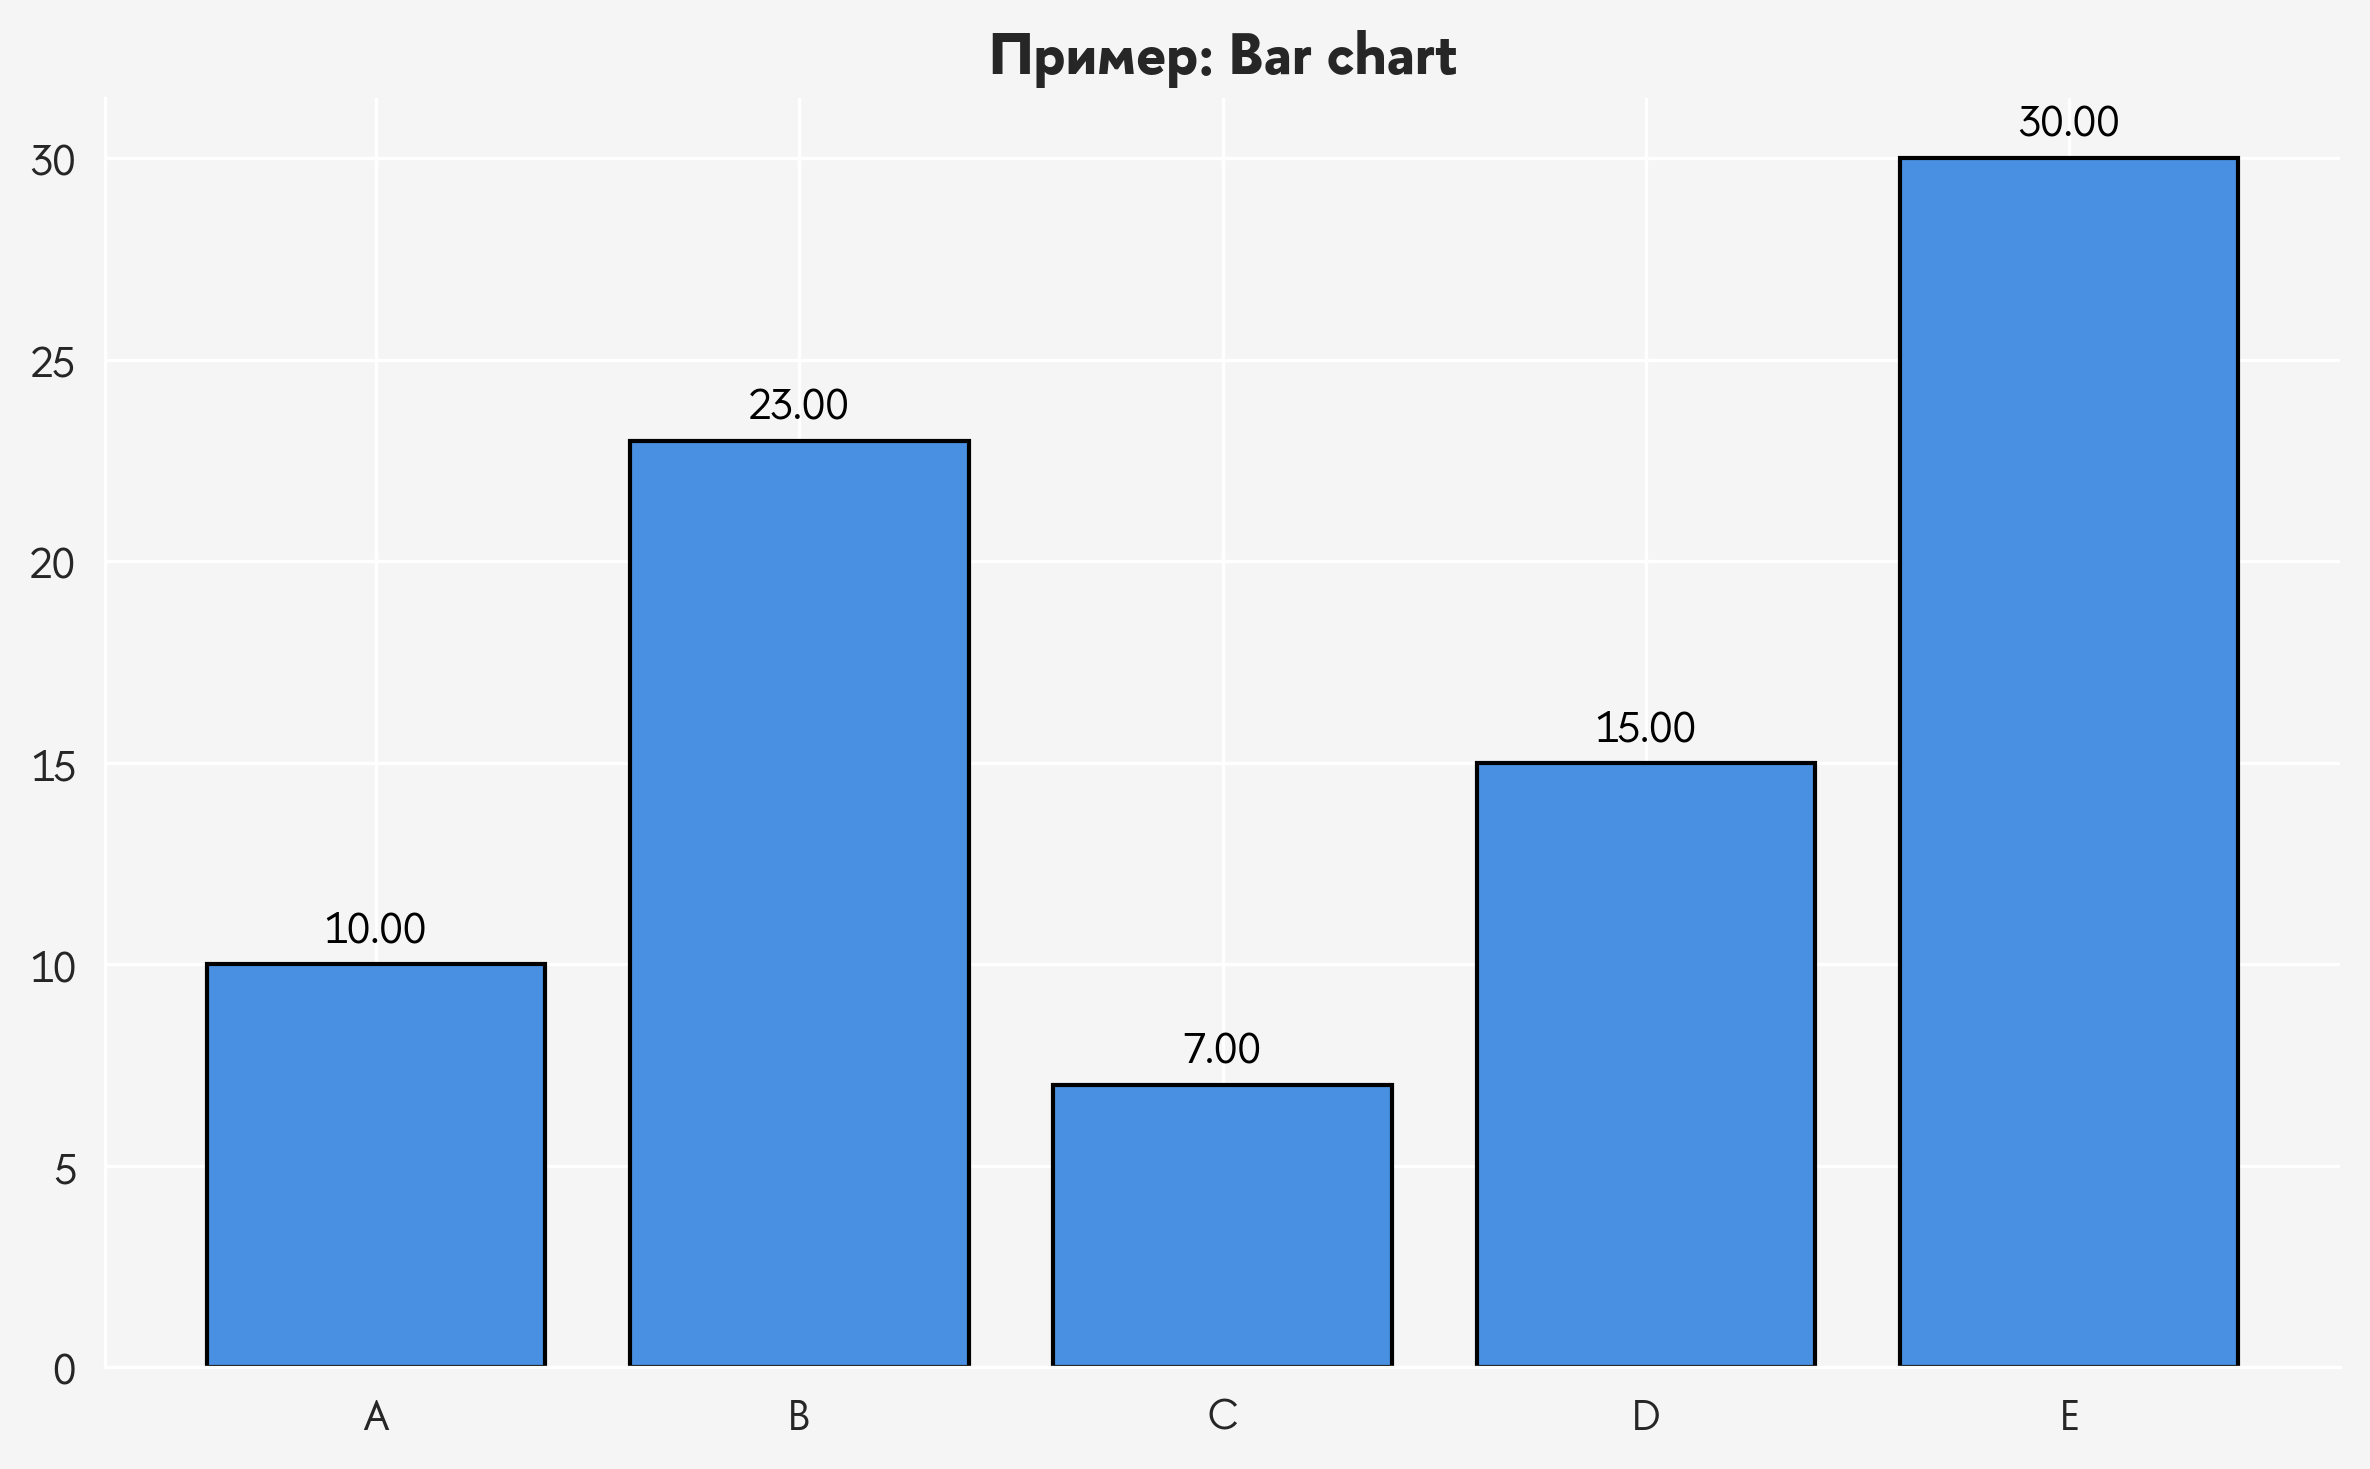

2) Line chart: линейный тренд с шумом


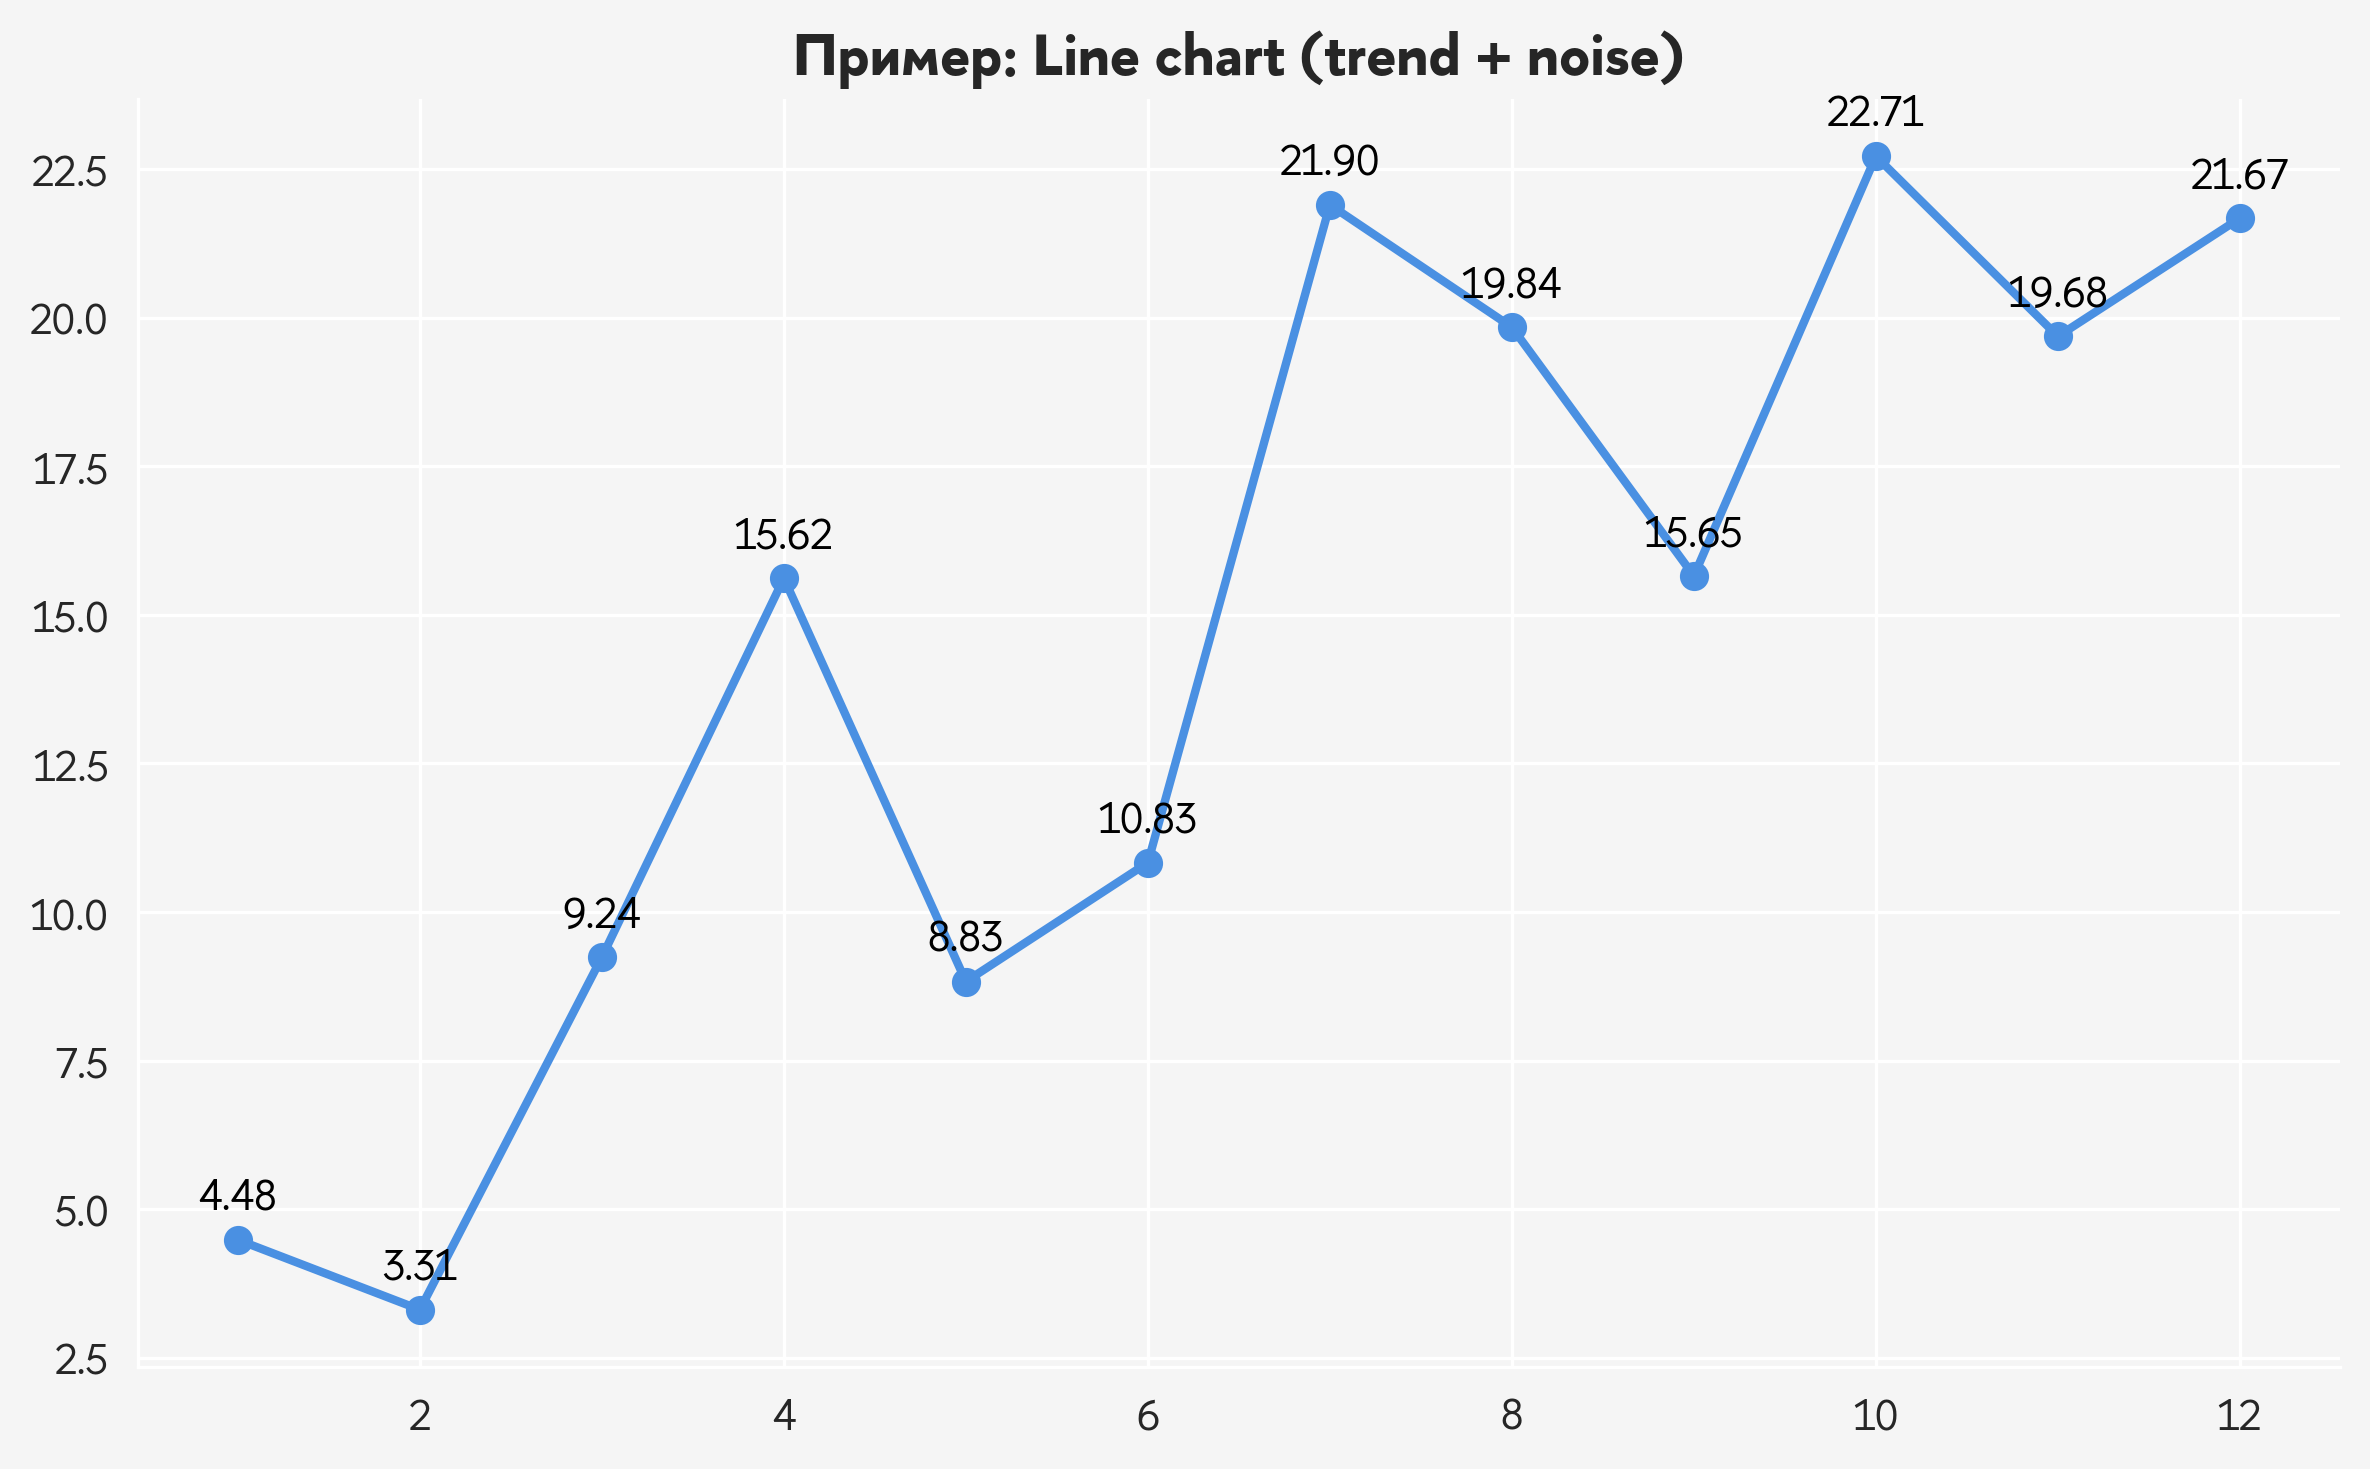

3) Stacked bar with success part


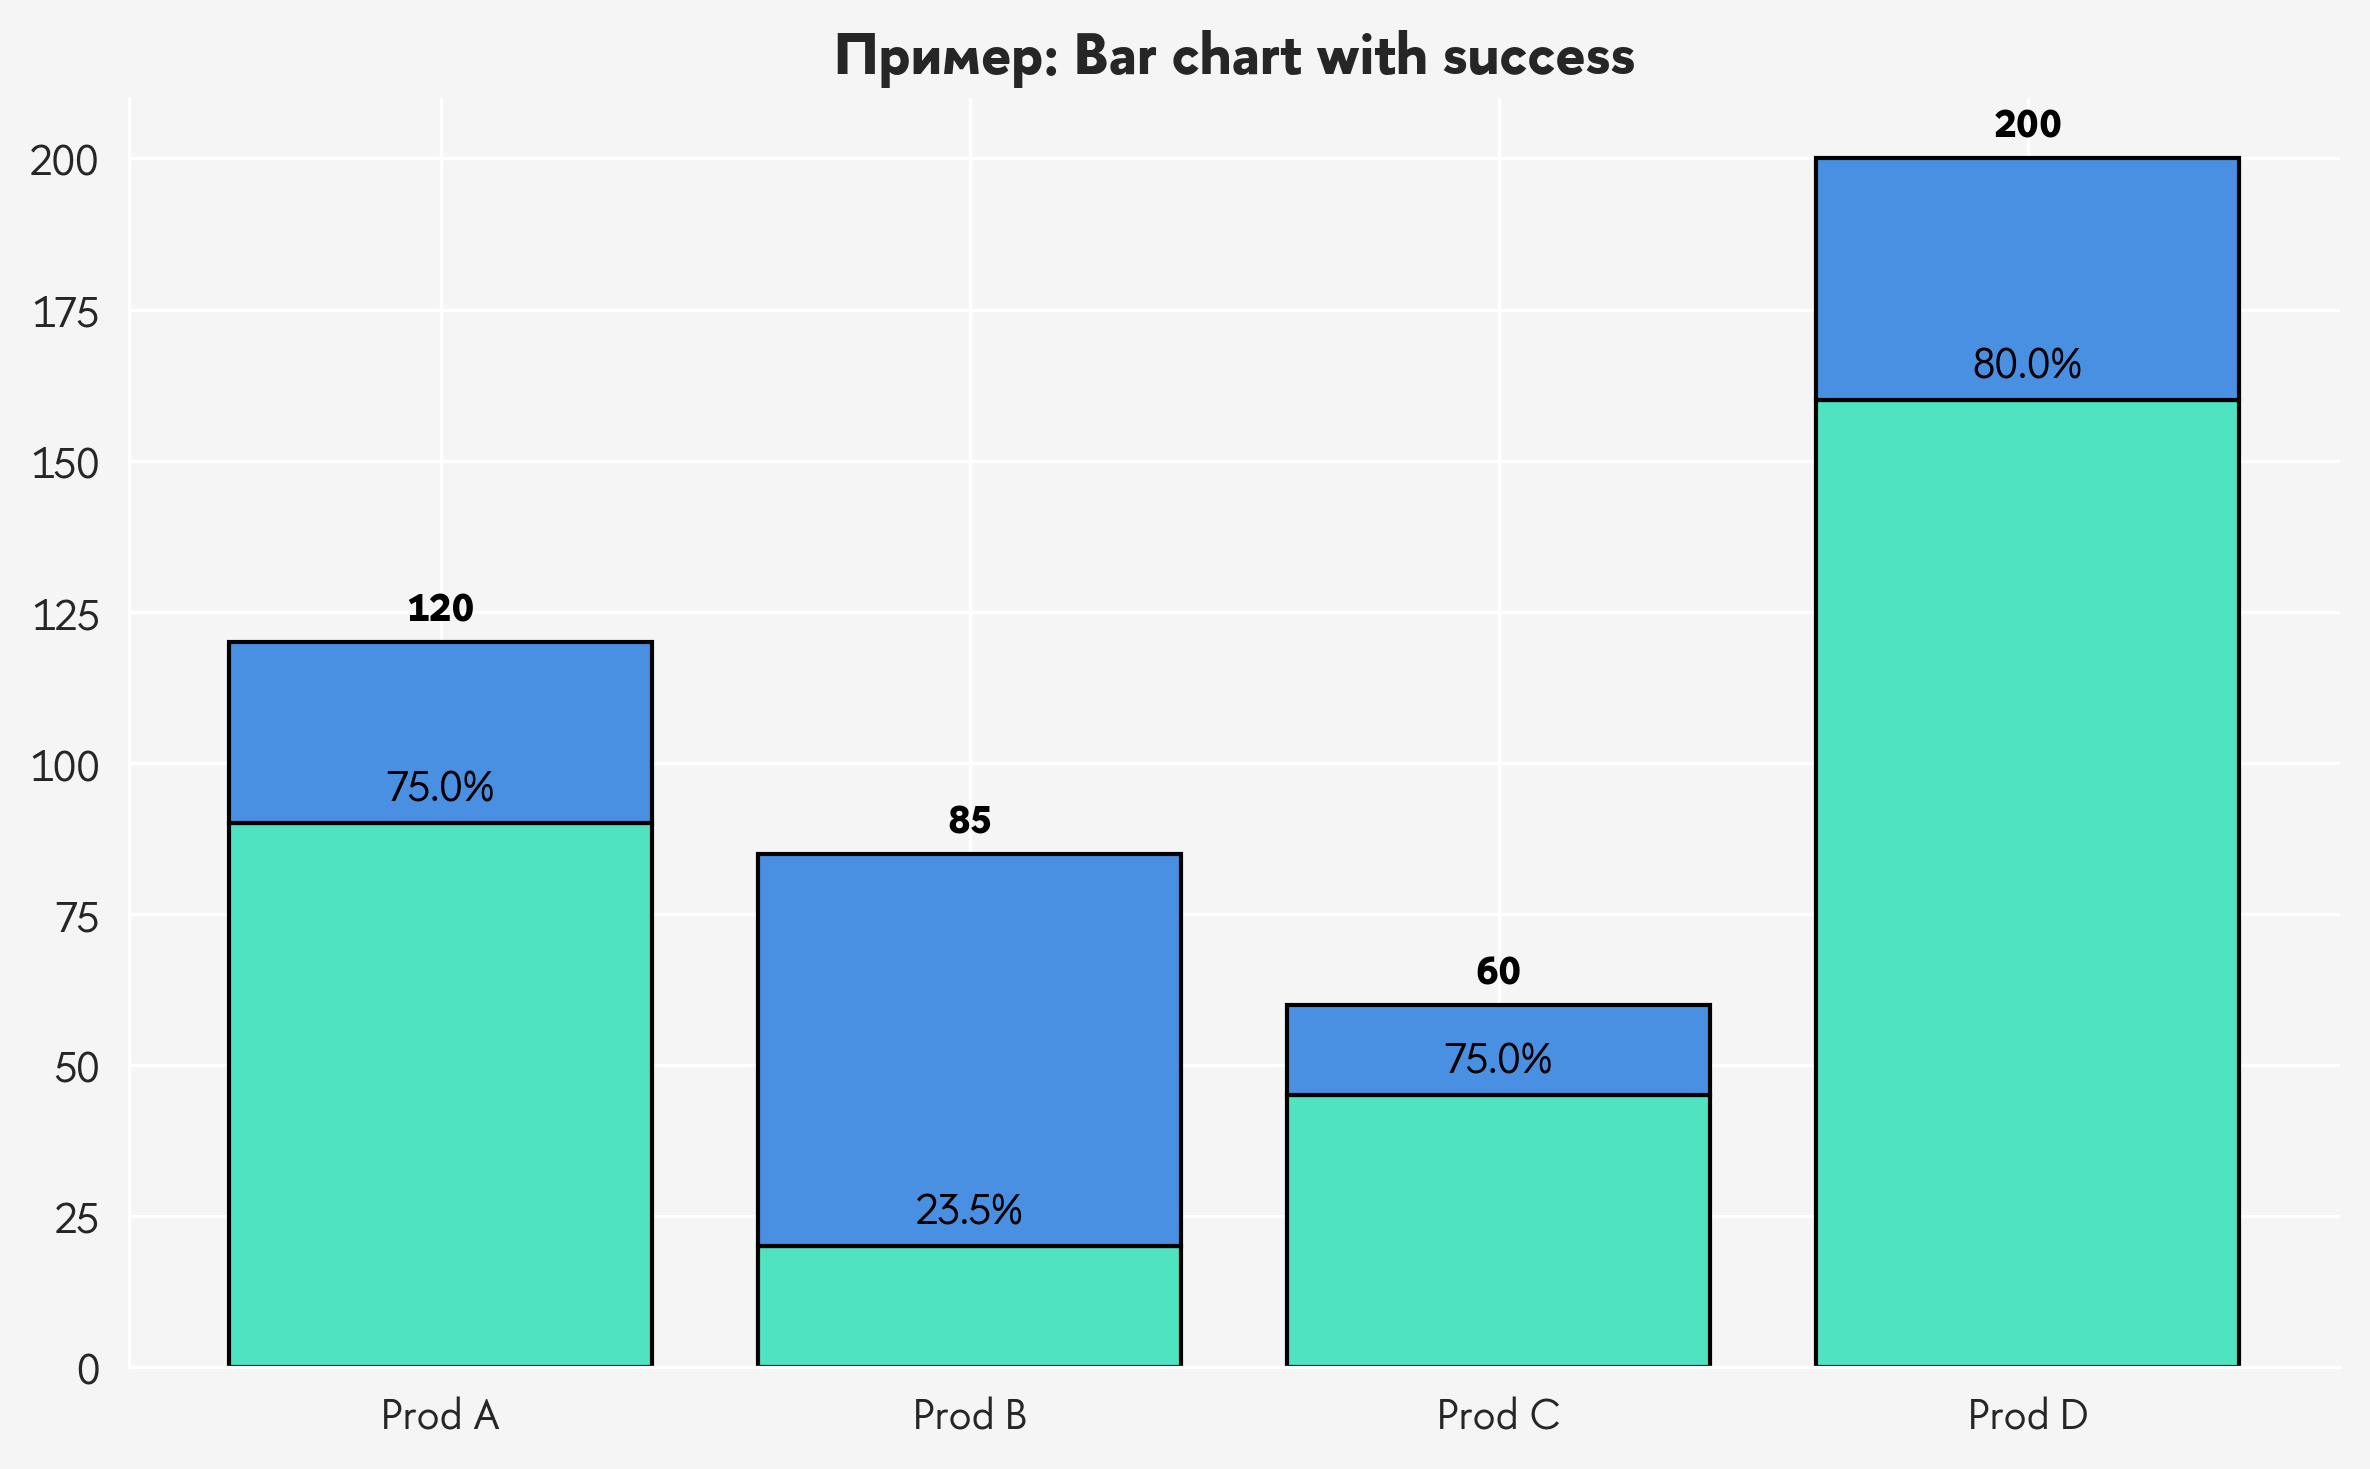

4) Histogram of generated series


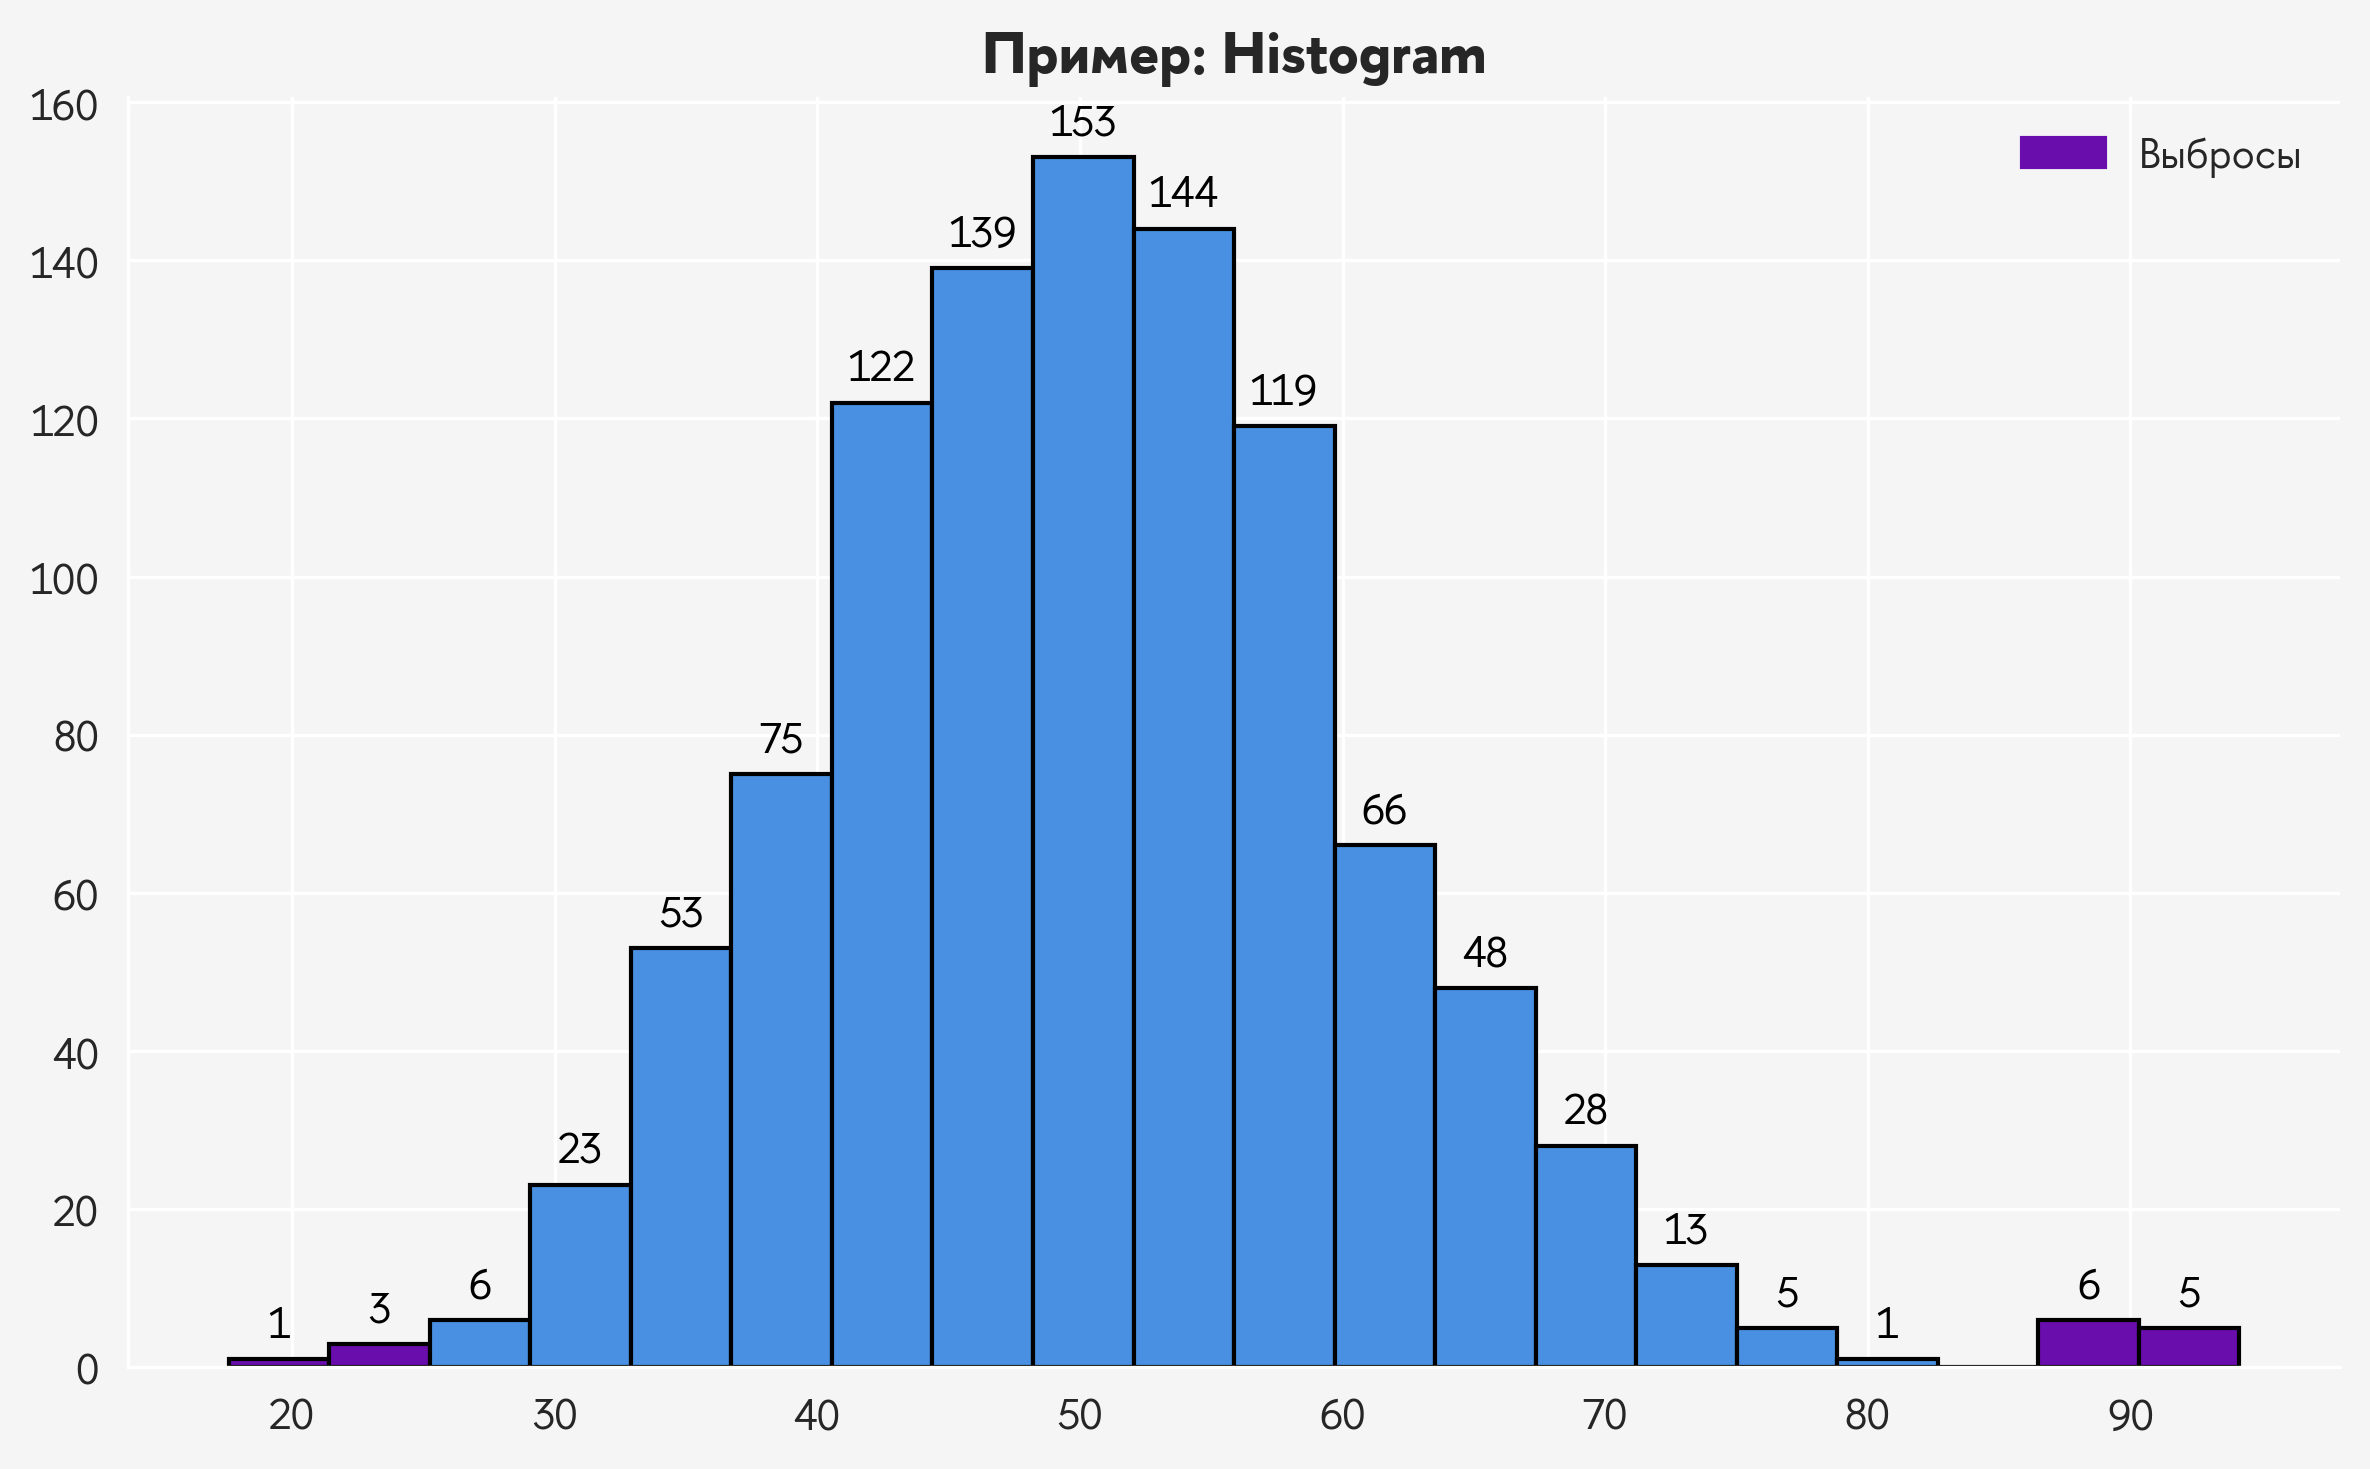

5a) Heatmap (0..1) with NaN cell


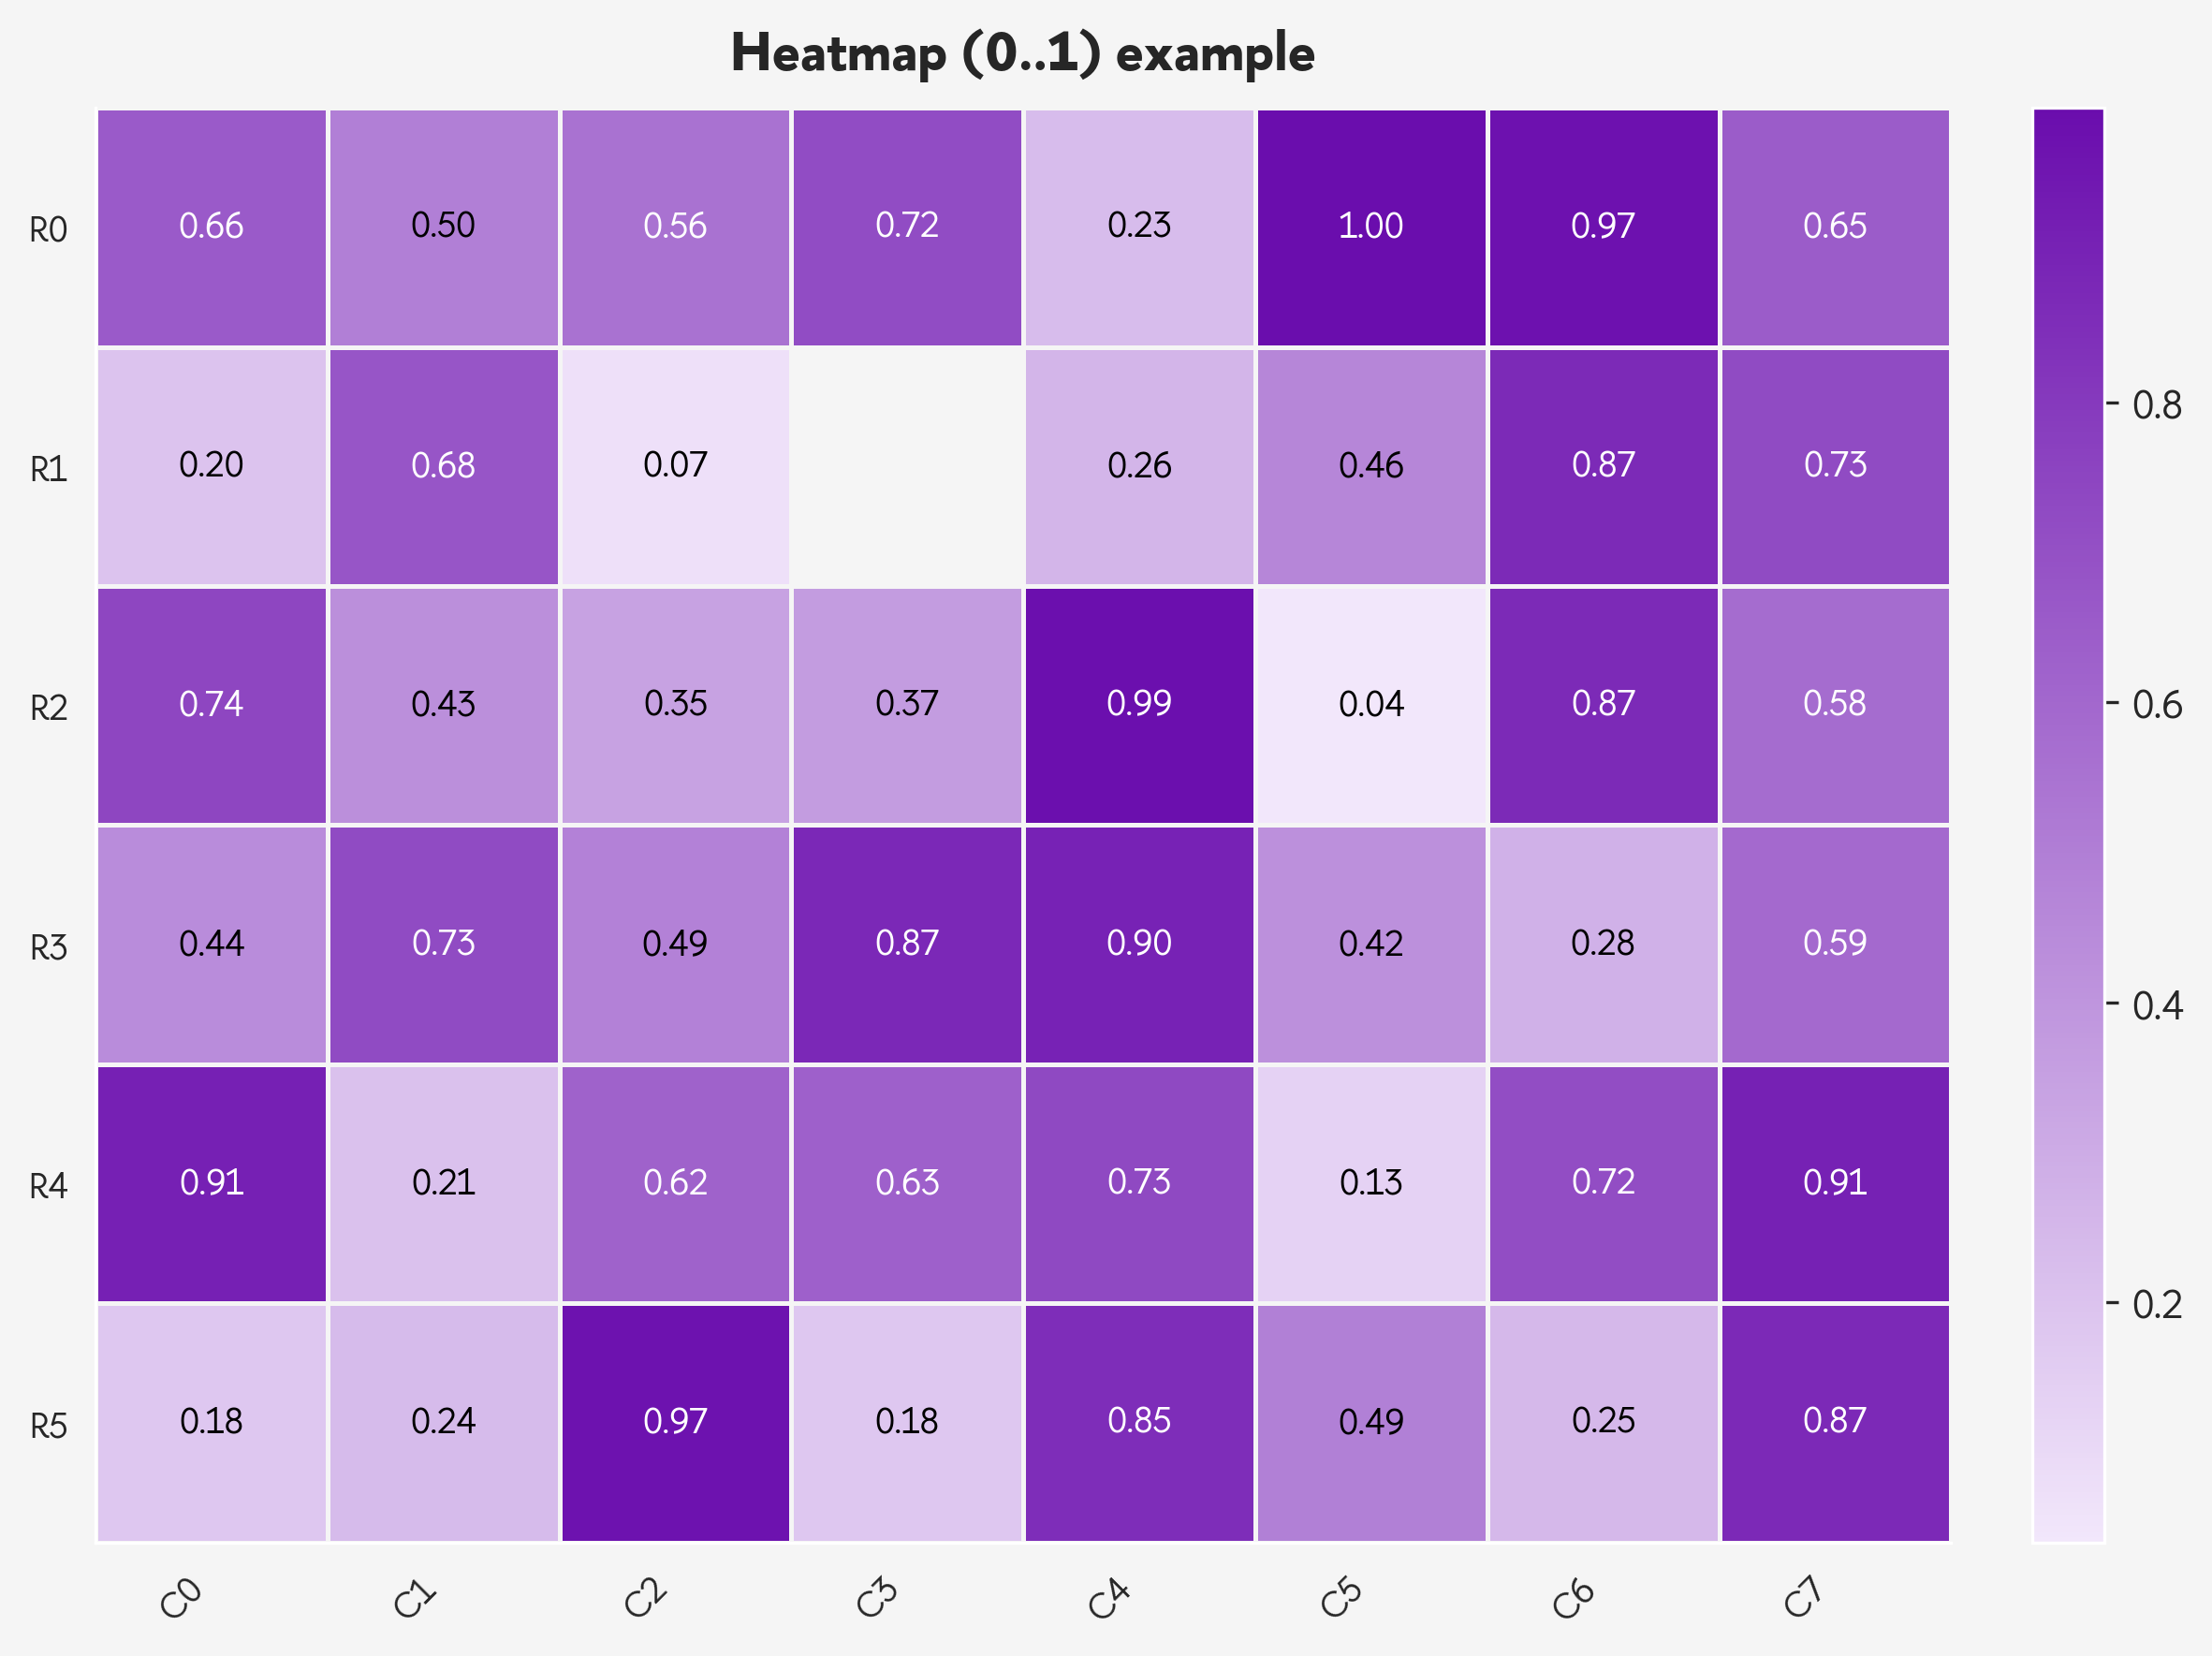

5b) Symmetric heatmap (-1..1)


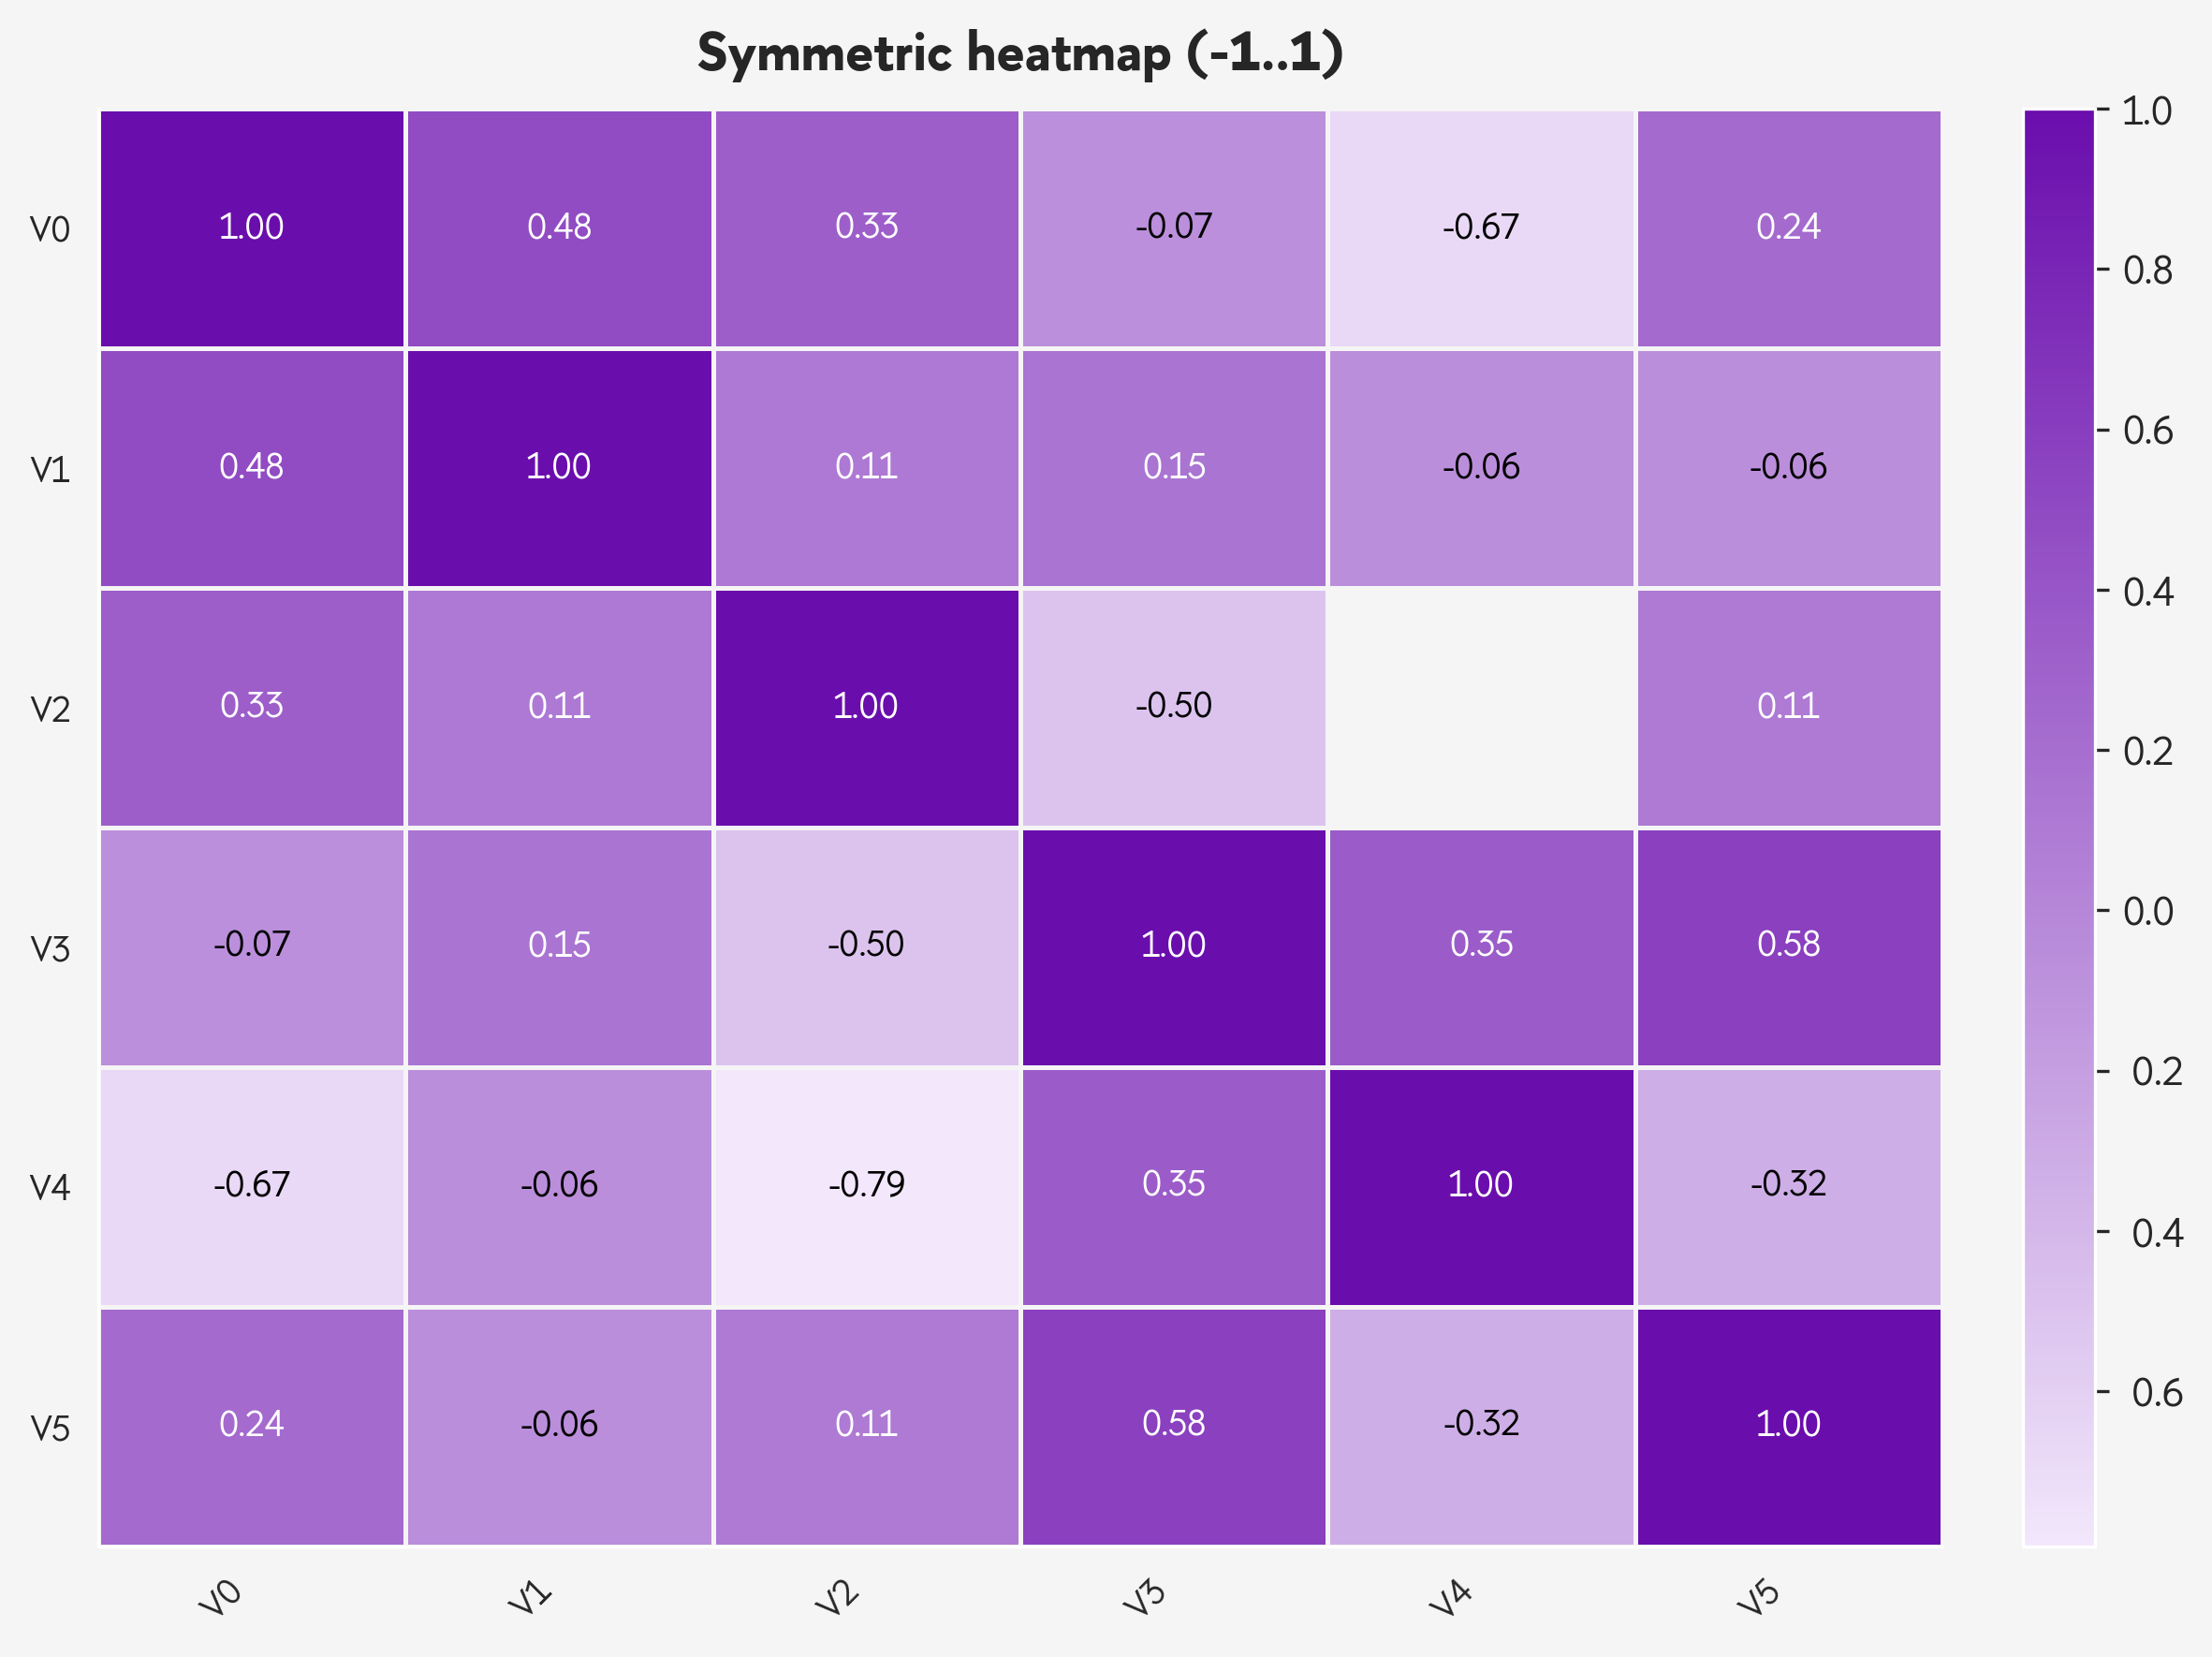

Генерация тестовых графиков завершена.


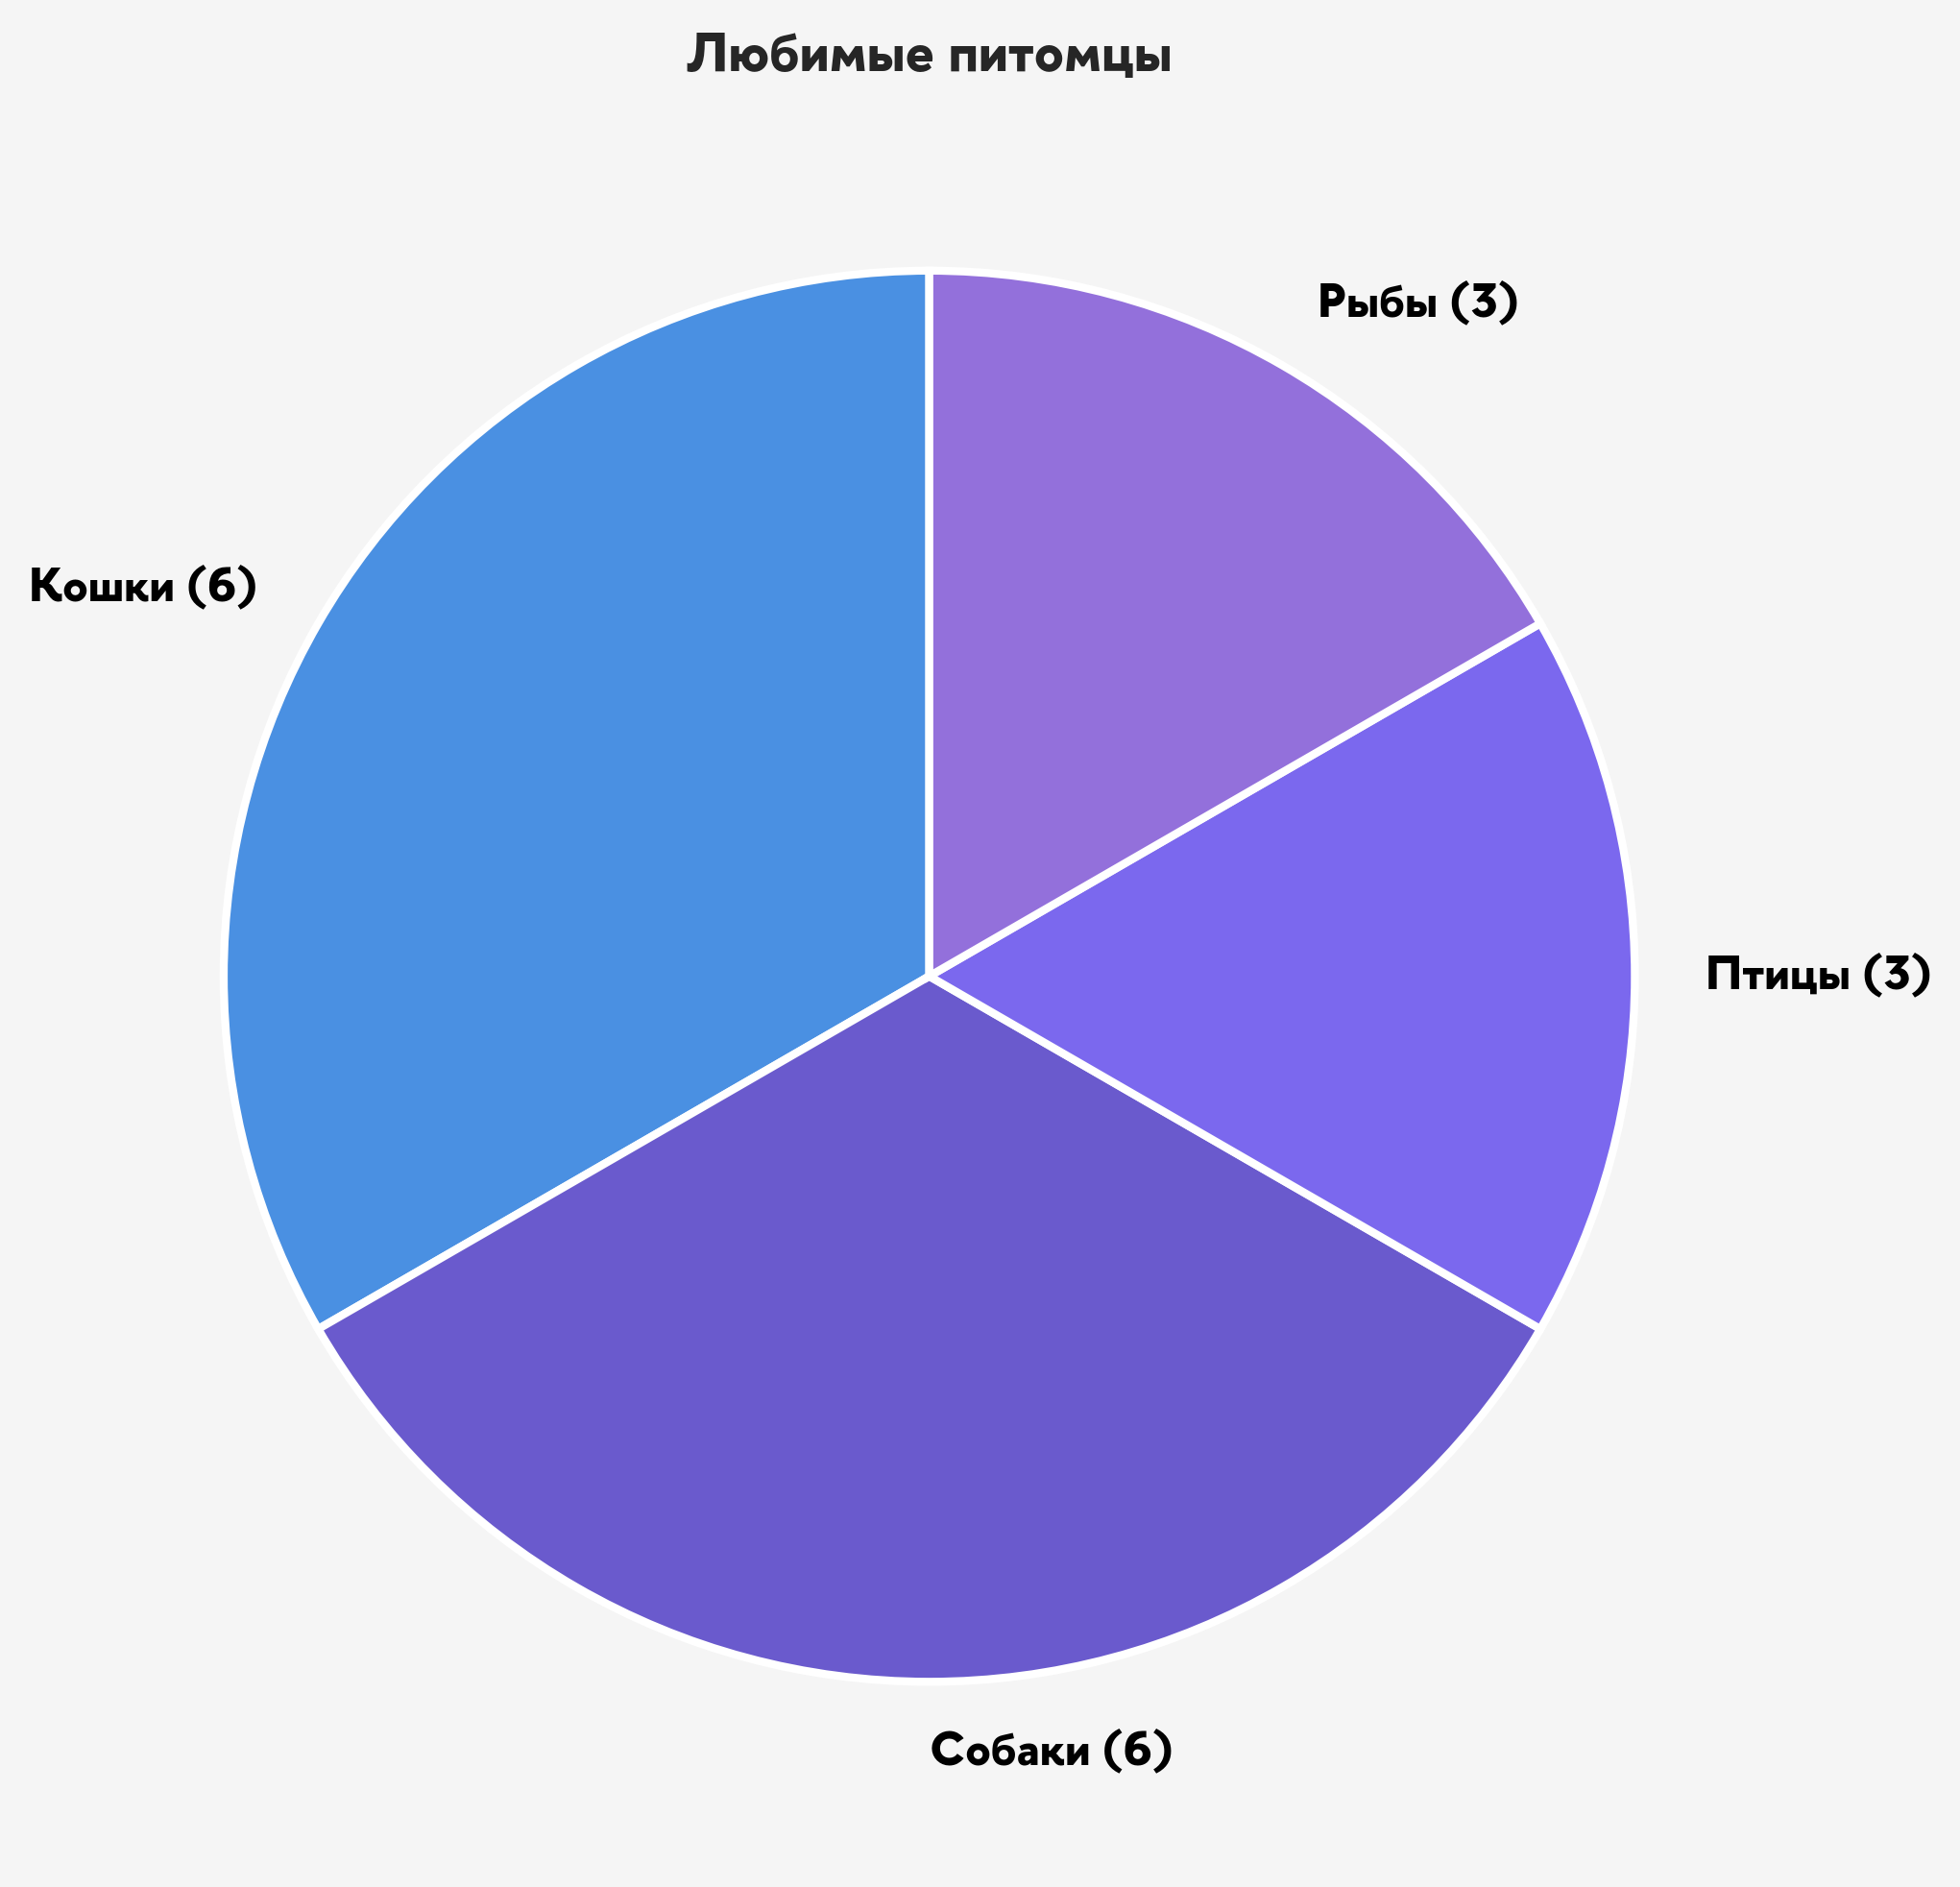

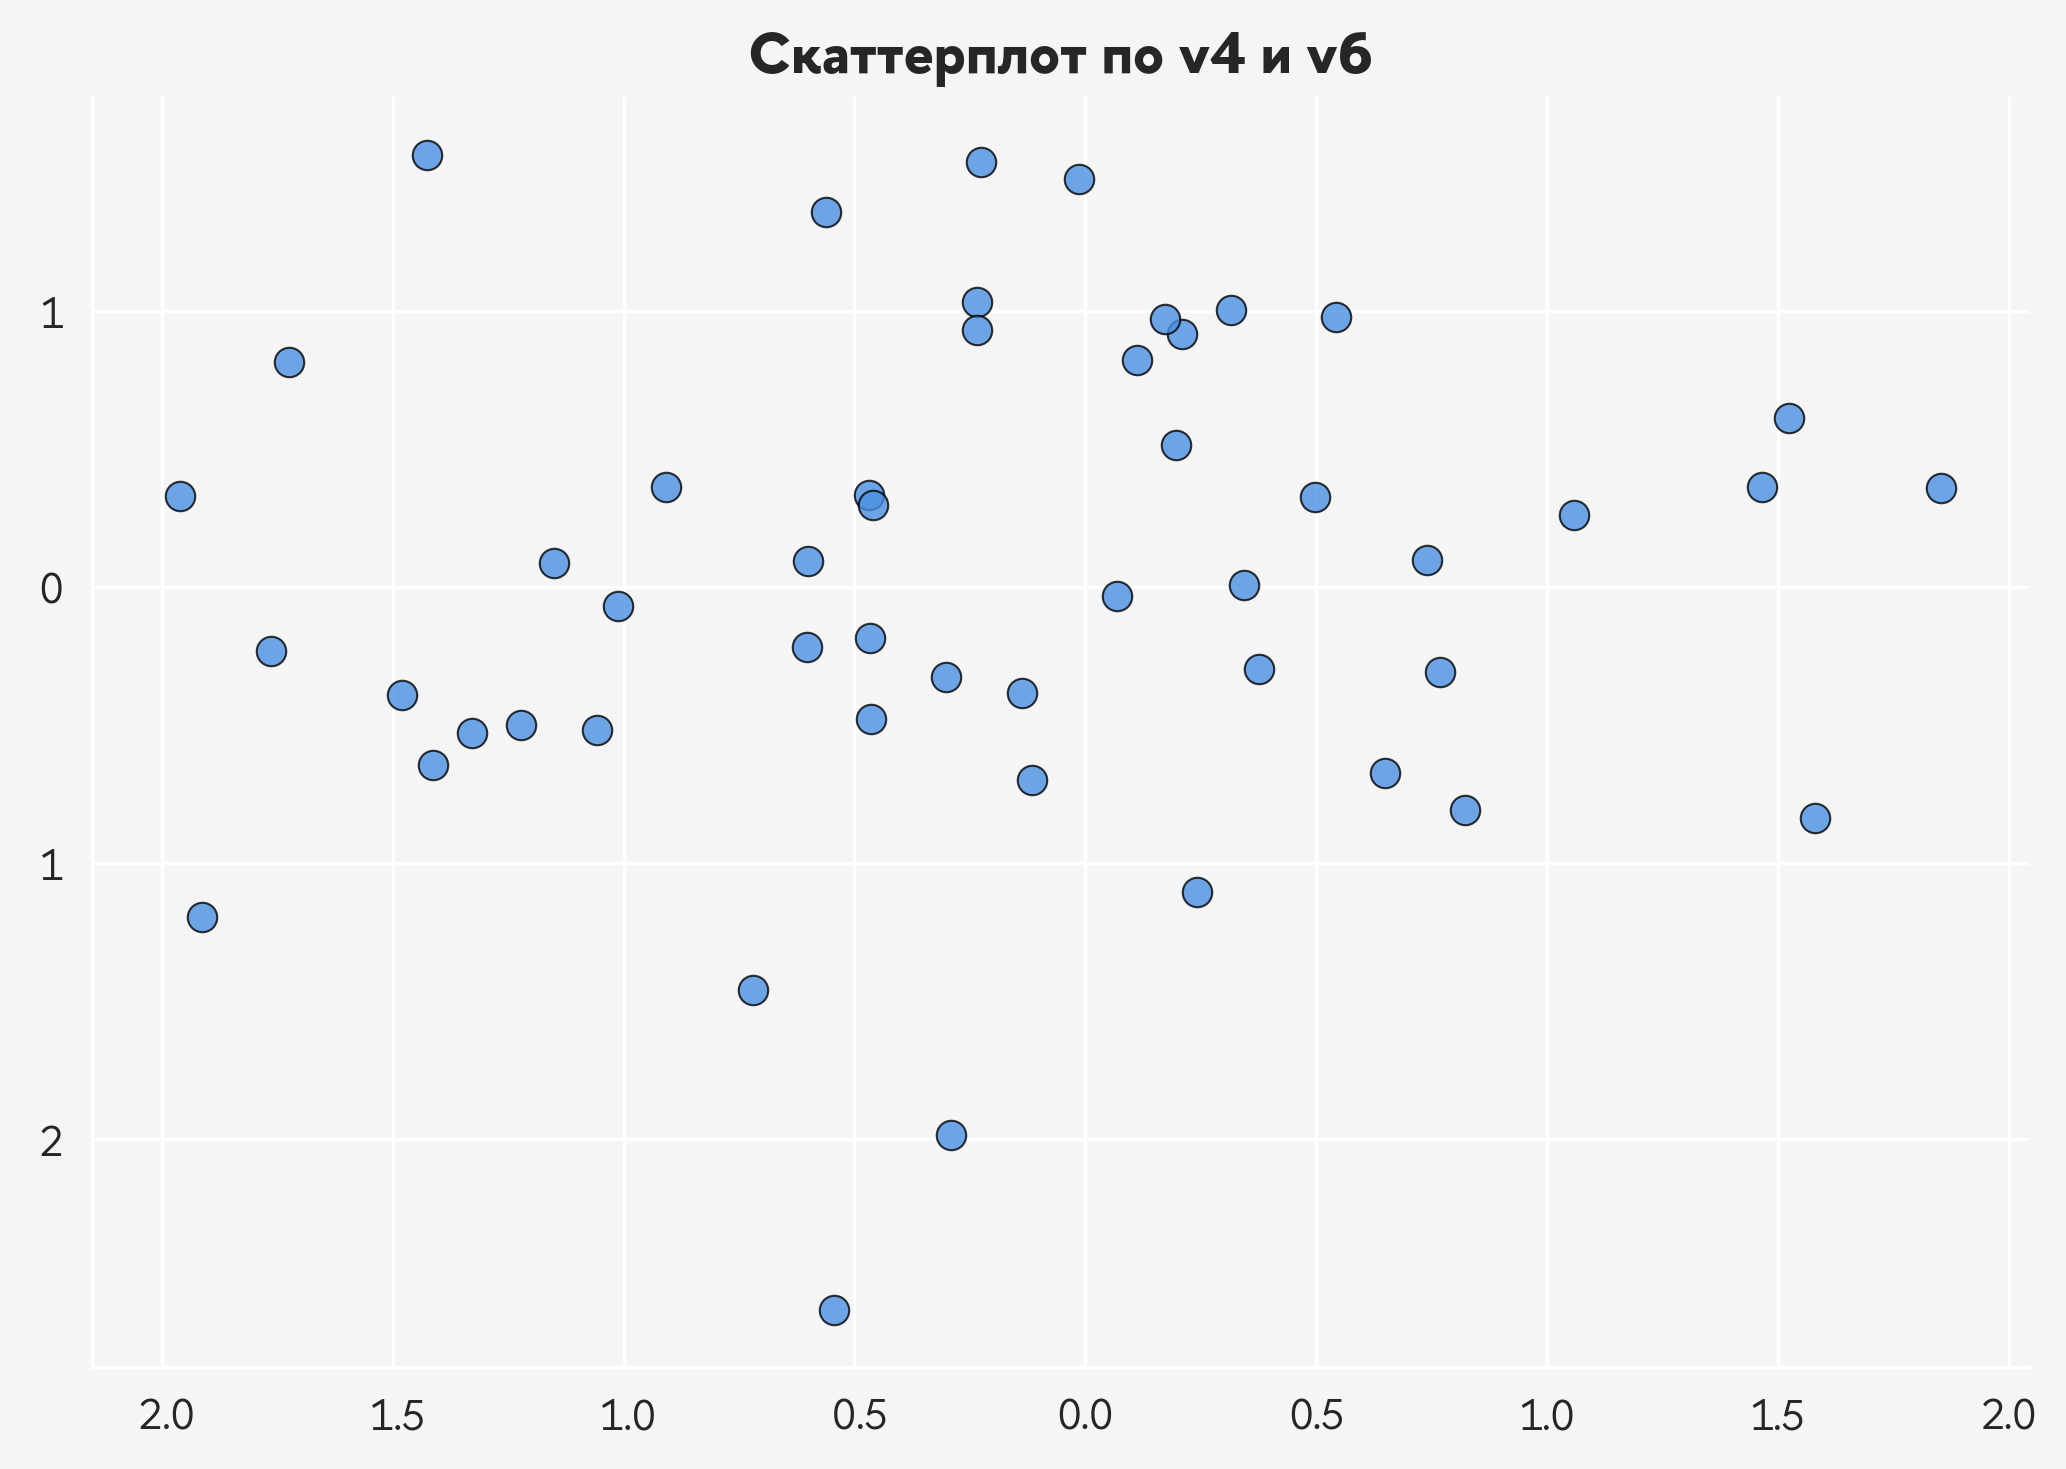

In [4]:
import random

np.random.seed(42)
random.seed(42)

# 1) Bar chart
cats = ['A', 'B', 'C', 'D', 'E']
vals = [10, 23, 7, 15, 30]

print("1) Bar chart: categories A..E")
graphics.plot_bar_chart(cats, vals, title="Пример: Bar chart")

# 2) Line chart (тренд + шум)
x_line = list(range(1, 13))
y_line = [2 * xi + np.random.normal(scale=5) for xi in x_line]
print("2) Line chart: линейный тренд с шумом")
graphics.plot_line_chart(x_line, y_line, title="Пример: Line chart (trend + noise)")

# 3) Bar chart with success
cats2 = ['Prod A', 'Prod B', 'Prod C', 'Prod D']
totals = [120, 85, 60, 200]
success = [90, 20, 45, 160]
print("3) Stacked bar with success part")
graphics.plot_bar_chart_with_success(cats2, totals, success, title="Пример: Bar chart with success")

# 4) Histogram (normal + some outliers)
series = np.concatenate([np.random.normal(loc=50, scale=10, size=1000), np.random.normal(loc=90, scale=2, size=10)])
print("4) Histogram of generated series")
graphics.norm_hist(series, bins=20, title="Пример: Histogram", podpisi=True, outliers_min=28, outliers_max=86)

# 5) Heatmaps
# 5a) Positive-only heatmap (0..1)
mat_pos = np.random.rand(6, 8)
mat_pos[1, 3] = np.nan  # показаем NaN
print("5a) Heatmap (0..1) with NaN cell")
graphics.plot_heatmap(mat_pos, x_labels=[f'C{i}' for i in range(mat_pos.shape[1])], y_labels=[f'R{i}' for i in range(mat_pos.shape[0])], title="Heatmap (0..1) example")

# 5b) Symmetric heatmap (-1..1) with center=0
mat_sym = np.random.uniform(-1, 1, size=(6,6))
# сделаем её симметричной for visual
mat_sym = (mat_sym + mat_sym.T) / 2
np.fill_diagonal(mat_sym, 1.0)
mat_sym[2,4] = np.nan
print("5b) Symmetric heatmap (-1..1)")
graphics.plot_heatmap(mat_sym, x_labels=[f'V{i}' for i in range(mat_sym.shape[1])], y_labels=[f'V{i}' for i in range(mat_sym.shape[0])], title="Symmetric heatmap (-1..1)")

print("Генерация тестовых графиков завершена.")

# 6 pie chart
data = pd.Series([
    "Кошки", "Собаки", "Собаки", "Птицы", "Кошки", "Кошки",
    "Собаки", "Птицы", "Кошки", "Рыбы", "Рыбы", "Собаки",
    "Кошки", "Кошки", "Собаки", "Рыбы", "Птицы", "Собаки"
])

# Вызов функции
graphics.norm_pie(
    data,
    title="Любимые питомцы"
)

# 7 scatter plot
np.random.seed(42)
x = np.random.randn(50)
y = np.random.randn(50)
cats = np.random.choice(["Кошки", "Собаки", "Птицы"], size=50)

# Вызов
graphics.norm_scatter(x, y, title="Скаттерплот по v4 и v6")


